<a href="https://colab.research.google.com/github/pikey-msc/RiesgosFinancieros/blob/master/2027-1/DeltaGamma_Integraci%C3%B3n_pro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📐 Riesgo de Mercado Paramétrico: Delta-Normal y Delta-Gamma — Portafolio Integrado

**Riesgos Financieros — 2026-1**

Este cuaderno mide el **riesgo de mercado** de un portafolio con **ocho** tipos de instrumentos — acciones, divisas, CETES, Bonos M, Bondes D, forwards de tipo de cambio, forwards de índices, swaps y opciones de tasa de interés — con **tres métodos paramétricos**, de menos a más preciso:

1. **Delta-Normal** — aproxima el valor del portafolio como una función *lineal* de los factores de riesgo.
2. **Delta-Gamma-Normal** — agrega el término *cuadrático* (convexidad), pero sigue asumiendo que la pérdida resultante es normal.
3. **Delta-Gamma-Cornish-Fisher** — usa la verdadera asimetría que introduce el término cuadrático para ajustar el cuantil (ya no asume normalidad).

### 🗺️ Ruta del cuaderno
1. **Funciones auxiliares** — interpolación de curvas, un motor **homologado** de *Griegas* (Delta y Gamma "dollar", el mismo código para los 8 instrumentos), y las fórmulas de VaR/CVaR de los 3 métodos.
2. **Parámetros** — fecha, nivel de confianza, método de interpolación, **rutas de archivo**, y la cartera de cada instrumento — todo como **campos de formulario** 📋.
3. **Carga e integración de datos**.
4. **Valuación** de cada instrumento y de sus sensibilidades (Delta, Gamma, Theta).
5. **Medición de riesgo por instrumento** — VaR/CVaR con los 3 métodos, a nivel contrato y a nivel instrumento-factor de riesgo.
6. **Integración del portafolio** — cómo se ensambla la matriz Delta-Gamma conjunta, y el riesgo total por factor de riesgo y total del portafolio.
7. **Resumen integral** a los 6 niveles: contrato, instrumento-factor de riesgo, total instrumento, total instrumento-factor de riesgo, total portafolio por factor de riesgo, y total portafolio.

> 🛠️ **Sobre esta revisión:** la versión original mezclaba R y Python, con la implementación completa en R pero la traducción a Python **incompleta e inconsistente** entre instrumentos — algunos instrumentos sí calculaban VaR/CVaR Delta-Normal y otros no, ninguno tenía Cornish-Fisher terminado en Python, y la integración final a nivel portafolio estaba rota (la celda de "Riesgo Integral por factor de riesgo" repetía el mismo cálculo genérico cinco veces). Aquí se reescribió **todo en Python puro**, homologando el cálculo de Griegas y de las 3 metodologías de VaR/CVaR con una sola función reutilizable para los 8 instrumentos, y completando la integración a nivel portafolio.

**Cómo usarlo:** ejecuta todo con *Entorno de ejecución → Ejecutar todas* la primera vez (tarda unos minutos por las descargas de Yahoo Finance); después cambia cualquier campo de formulario y vuelve a ejecutar desde ahí hacia abajo.


In [1]:
# @title 📦 Clonar el repositorio del curso (datos e insumos) { display-mode: "form" }
!rm -rf RiesgosFinancieros
!git clone "https://github.com/pikey-msc/RiesgosFinancieros/"


Cloning into 'RiesgosFinancieros'...
remote: Enumerating objects: 1413, done.
remote: Counting objects: 100% (206/206), done.
remote: Compressing objects: 100% (138/138), done.
remote: Total 1413 (delta 136), reused 68 (delta 68), pack-reused 1207 (from 2)
Receiving objects: 100% (1413/1413), 73.53 MiB | 12.54 MiB/s, done.
Resolving deltas: 100% (870/870), done.
Updating files: 100% (490/490), done.


## 🧮 Marco teórico (1/2): Delta-Normal, Delta-Gamma-Normal y Cornish-Fisher

Para cualquier instrumento, aproximamos su cambio de valor $\Delta V$ ante un movimiento $\Delta x$ de sus factores de riesgo con una expansión de Taylor:

$$ \Delta V \approx \underbrace{\delta^\top \Delta x}_{\text{término lineal (Delta)}} + \underbrace{\tfrac{1}{2}\,\Delta x^\top \Gamma\, \Delta x}_{\text{término cuadrático (Gamma)}} $$

donde $\delta$ (vector) y $\Gamma$ (matriz) son la primera y segunda derivada del valor respecto a los factores de riesgo. Usamos como factores de riesgo los **retornos logarítmicos** $\Delta x = \Delta\ln X$ de cada curva/precio — por eso $\delta$ y $\Gamma$ aquí ya vienen en escala "dollar" ($\delta = \frac{\partial V}{\partial X}\cdot X_0$, $\Gamma = \frac{\partial^2 V}{\partial X^2}\cdot X_0 X_0^\top$): así $\delta^\top\Delta x$ y $\Delta x^\top\Gamma\Delta x$ ya están en las mismas unidades que $V$, sin reescalar nada después.

Si $\Delta x \sim N(0,\Sigma)$ (histórico de variaciones de los factores de riesgo), entonces:

### 1️⃣ Delta-Normal
Solo el término lineal: $\Delta V\approx \delta^\top\Delta x$, que es normal con media 0 y varianza $\sigma^2=\delta^\top\Sigma\delta$.
$$ VaR_{DN}=\sigma\cdot z_{1-\alpha} \qquad CVaR_{DN}=-\sigma\cdot\frac{\phi(z_\alpha)}{1-\alpha} $$
($z_p$ = cuantil $p$ de la normal estándar, $\phi$ = su densidad. $VaR$ y $CVaR$ salen como pérdidas, es decir, en signo negativo.)

### 2️⃣ Delta-Gamma-Normal
Se agrega el término cuadrático, pero se sigue aproximando la distribución resultante como normal, ajustando su **media** y su **varianza** con los primeros dos momentos de $\Delta x^\top\Gamma\Delta x$:

$$ \mu = \min\!\Big(0,\ \tfrac12\operatorname{tr}(\Gamma\Sigma) + \theta\Big) \qquad \sigma^2=\delta^\top\Sigma\delta+\tfrac12\operatorname{tr}\big((\Gamma\Sigma)^2\big) $$
$$ VaR_{DGN}=\mu+\sigma\cdot z_{1-\alpha} \qquad CVaR_{DGN}=\mu-\sigma\cdot\frac{\phi(z_\alpha)}{1-\alpha} $$

$\theta$ es la deriva determinista por el simple paso de un día (p. ej., el devengo de un bono), y se acota a $\le 0$: solo se le "regala" al portafolio la parte de la deriva que es pérdida seguro, nunca ganancia.

### 3️⃣ Delta-Gamma-Cornish-Fisher
$\Delta x^\top\Gamma\Delta x$ no es realmente normal — tiene **asimetría**. En vez de ignorarla (como en el método 2), la usamos para corregir el cuantil normal con una expansión de Cornish-Fisher:

$$ \xi=\frac{\operatorname{tr}\big((\Gamma\Sigma)^3\big)+3\,\delta^\top\Sigma\Gamma\Sigma\delta}{\sigma^3} \qquad z_{CF}=z_{1-\alpha}+\frac{z_{1-\alpha}^2-1}{6}\,\xi $$
$$ VaR_{DGCF}=\mu+\sigma\cdot z_{CF} \qquad CVaR_{DGCF}=\mu-\sigma\cdot\frac{\phi(z_{CF})}{\Phi(z_{CF})} $$

($\xi$ es el coeficiente de asimetría estandarizado de la distribución cuadrática. Nota que el $CVaR$ de Cornish-Fisher usa $\Phi(z_{CF})$ en vez de $(1-\alpha)$ en el denominador — es la probabilidad de cola que el propio ajuste de Cornish-Fisher implica, más consistente con el cuantil ya corregido que la probabilidad nominal.)

> 🔎 Los tres métodos son **anidados**: Delta-Normal es el caso Delta-Gamma-Normal con $\Gamma=0$; Delta-Gamma-Normal es el caso Cornish-Fisher con $\xi=0$. Por eso una sola función homologada (`riesgo_parametrico`, más abajo) calcula los tres a la vez.


## 🧩 Marco teórico (2/2): integrar Delta y Gamma de varios instrumentos

Cada instrumento tiene su propio vector $\delta_i$ y su propia matriz $\Gamma_i$, del tamaño de **sus propios** factores de riesgo (p. ej., Bondes D usa 3 factores por flujo: fondeo, curva de descuento y spread). Para el portafolio completo:

- El vector Delta se **concatena**: $\delta_{port}=(\delta_1,\delta_2,\ldots,\delta_8)$ — un vector con tantas entradas como la suma de factores de todos los instrumentos.
- La matriz Gamma se acomoda en **bloques diagonales**:

$$ \Gamma_{port}=\begin{pmatrix}\Gamma_1 & 0 &\cdots & 0\\ 0 & \Gamma_2 & \cdots & 0\\ \vdots & & \ddots & \vdots \\ 0&0&\cdots&\Gamma_8\end{pmatrix} $$

Los bloques **fuera de la diagonal son cero** porque el valor de un instrumento no depende de los factores de riesgo de otro instrumento (el precio de una acción no afecta la valuación de un swap). Dentro de cada bloque $\Gamma_i$, sí puede haber términos cruzados (p. ej., la curva de descuento y el spread de un mismo flujo de Bondes D sí interactúan).

**Cuando queremos el riesgo de un solo *tipo* de factor** (p. ej. "todo lo que es riesgo de tasa de interés", sin importar de qué instrumento venga), no basta con sumar los $\delta$ de esos factores: también hay que **enmascarar** $\Gamma_{port}$, dejando en cero cualquier entrada que involucre un factor fuera de ese grupo — así el término cuadrático $\Delta x^\top\Gamma\Delta x$ solo captura la convexidad que en verdad viene de esos factores.

### 🖼️ Diagrama del proceso

```
 Curvas/precios históricos            Fecha de valuación
 (por instrumento)                    (nivel actual x₀)
        │                                    │
        ▼                                    ▼
 ┌─────────────────┐              ┌───────────────────────┐
 │  Σ = Cov(Δln X)  │              │  V₀ = valuación(x₀)    │
 │ (matriz de       │              │  δ  = ∂V/∂ln(x) · x₀   │◄── bump ±h en
 │  varianza-cov.)  │              │  Γ  = ∂²V/∂ln(x)² · x₀x₀ᵀ│    log(factor)
 └────────┬─────────┘              │  θ  = ∂V/∂t (1 día)    │    (motor homologado)
          │                        └───────────┬───────────┘
          │                                    │
          └───────────────┬────────────────────┘
                           ▼
              ┌─────────────────────────┐
              │  por instrumento:        │
              │  VaR/CVaR  DN, DGN, DGCF │
              │  (nivel contrato y       │
              │   contrato-factor)       │
              └────────────┬─────────────┘
                           │  concatenar δ, armar Γ en bloques
                           ▼
              ┌─────────────────────────┐
              │  Portafolio integrado:   │
              │  δ_port, Γ_port (bloques)│
              │  → VaR/CVaR total, y     │
              │  por factor de riesgo    │
              │  (enmascarando δ y Γ)    │
              └─────────────────────────┘
```


# 🔧 Funciones auxiliares

- **`talamb` / `approx`** — interpolación de curvas (tasa alambrada / lineal).
- **`greeks_dollar`** — el motor homologado de Griegas: dadas una función de valuación vectorizada y los niveles actuales de sus propios factores, regresa Delta y Gamma "dollar" (con todos los términos cruzados) vía diferencias centrales en el logaritmo de cada factor. Se usa igual para los 8 instrumentos.
- **`theta_dias`** — sensibilidad al simple paso de un día (bump del plazo, no de una tasa/precio).
- **`riesgo_parametrico`** — dado $\delta$, $\Gamma$, $\theta$ y $\Sigma$, calcula VaR y CVaR con los 3 métodos (Delta-Normal, Delta-Gamma-Normal, Delta-Gamma-Cornish-Fisher).


In [2]:
# @title Interpolación: talamb() y approx() { display-mode: "both" }
import numpy as np


def approx(x, y, new_x):
    """Interpolación lineal simple (equivalente al `approx()` de R)."""
    return np.interp(new_x, x, y)


def talamb(nodos, curva, plazos):
    """
    Interpola tasas de interés de forma consistente con las tasas forward
    implícitas entre nodos (método "tasa alambrada", estándar del mercado
    mexicano). Fuera del rango de `nodos` se sostiene el valor del nodo más
    cercano (no se extrapola).
    """
    nodos = np.asarray(nodos, dtype=float).flatten()
    curva = np.asarray(curva, dtype=float).flatten()
    plazos = np.asarray(plazos, dtype=float).flatten()

    sorted_indices = np.argsort(nodos)
    nodos_sorted = nodos[sorted_indices]
    curva_sorted = curva[sorted_indices]

    indices = np.searchsorted(nodos_sorted, plazos) - 1
    indices[indices < 0] = 0
    indices[indices >= len(nodos_sorted) - 1] = len(nodos_sorted) - 2

    nodos_i = nodos_sorted[indices]
    nodos_i_plus_1 = nodos_sorted[indices + 1]
    TC_interp = curva_sorted[indices]
    TL_interp = curva_sorted[indices + 1]

    TF = np.where(plazos < nodos_sorted[0], curva_sorted[0],
             np.where(plazos > nodos_sorted[-1], curva_sorted[-1],
                      ((((1 + TL_interp * nodos_i_plus_1 / 360) / (1 + TC_interp * nodos_i / 360)) **
                        ((plazos - nodos_i) / (nodos_i_plus_1 - nodos_i)) *
                        (1 + TC_interp * nodos_i / 360)) - 1) * 360 / plazos))

    return TF


In [3]:
# @title 🧮 Motor homologado de Griegas: greeks_dollar() y theta_dias() { display-mode: "both" }
H_BUMP = 1e-4  # tamaño del brinco (en log) para las diferencias centrales


def greeks_dollar(f, x0_cols, h=H_BUMP):
    """
    Delta y Gamma "dollar" de una función de valuación vectorizada `f`,
    respecto al LOGARITMO de cada uno de sus propios factores de riesgo.

    f(*args): recibe k_own arreglos (uno por factor, todos del mismo
        tamaño = número de posiciones/flujos) y regresa un arreglo del
        mismo tamaño con el valor de cada posición/flujo.
    x0_cols: lista de k_own arreglos con el nivel ACTUAL de cada factor.

    Se perturba cada factor multiplicativamente (x*exp(±h)) -- consistente
    con que los factores de riesgo son retornos logarítmicos -- así el
    resultado ya es directamente la Delta/Gamma "dollar" que se usa en las
    fórmulas de VaR paramétrico, sin tener que reescalar nada después.

    Regresa (delta, gamma): `delta` es una lista de k_own arreglos;
    `gamma` es un dict {(k, l): arreglo} con TODAS las combinaciones
    (incluida la diagonal), para capturar también sensibilidades cruzadas
    entre los propios factores de un mismo instrumento.
    """
    x0_cols = [np.asarray(c, dtype=float) for c in x0_cols]
    k_own = len(x0_cols)
    base = f(*x0_cols)

    def bump(k, factor):
        cols = list(x0_cols)
        cols[k] = x0_cols[k] * factor
        return cols

    f_up = [f(*bump(k, np.exp(h))) for k in range(k_own)]
    f_dn = [f(*bump(k, np.exp(-h))) for k in range(k_own)]

    delta = [(f_up[k] - f_dn[k]) / (2 * h) for k in range(k_own)]
    gamma = {(k, k): (f_up[k] - 2 * base + f_dn[k]) / h ** 2 for k in range(k_own)}

    for k in range(k_own):
        for l in range(k + 1, k_own):
            def bump2(fk, fl):
                cols = list(x0_cols)
                cols[k] = x0_cols[k] * fk
                cols[l] = x0_cols[l] * fl
                return cols

            f_uu = f(*bump2(np.exp(h), np.exp(h)))
            f_ud = f(*bump2(np.exp(h), np.exp(-h)))
            f_du = f(*bump2(np.exp(-h), np.exp(h)))
            f_dd = f(*bump2(np.exp(-h), np.exp(-h)))
            cross = (f_uu - f_ud - f_du + f_dd) / (4 * h ** 2)
            gamma[(k, l)] = gamma[(l, k)] = cross

    return delta, gamma


def theta_dias(f_t, t0, dias=1.0):
    """
    Sensibilidad al simple paso de `dias` días (deriva determinista, sin
    tocar ningún factor de mercado): diferencia central de `f_t(t)`
    (función de valuación en términos del plazo t) alrededor de t0.
    """
    return (f_t(t0 + dias) - f_t(t0 - dias)) / (2 * dias)


def ensamblar_delta_gamma(delta_list, gamma_dict, k_own, n_own):
    """
    Arma el vector Delta (tamaño k_own*n_own) y la matriz Gamma
    (k_own*n_own x k_own*n_own, en bloques de tamaño n_own) de UN
    instrumento, a partir de lo que regresa `greeks_dollar` -- las
    columnas quedan en el mismo orden que las matrices de factores de
    riesgo de cada instrumento (todas las de un tipo de factor juntas).
    """
    delta_full = np.concatenate(delta_list)
    Gamma_full = np.zeros((k_own * n_own, k_own * n_own))
    for (k, l), val in gamma_dict.items():
        Gamma_full[k * n_own:(k + 1) * n_own, l * n_own:(l + 1) * n_own] = np.diag(val)
    return delta_full, Gamma_full


In [4]:
# @title 🧮 Función homologada: riesgo_parametrico() { display-mode: "both" }
from scipy.stats import norm


def riesgo_parametrico(delta, Gamma, theta, Sigma, alpha):
    """
    VaR y CVaR con los 3 métodos (Delta-Normal, Delta-Gamma-Normal,
    Delta-Gamma-Cornish-Fisher) -- ver Marco teórico -- dado:
      delta : vector Delta "dollar" (k,)
      Gamma : matriz Gamma "dollar" (k, k)
      theta : deriva determinista por un día (escalar)
      Sigma : matriz de varianza-covarianza de los factores (k, k)
      alpha : nivel de confianza
    """
    delta = np.asarray(delta, dtype=float).reshape(-1)
    Gamma = np.asarray(Gamma, dtype=float)
    Sigma = np.asarray(Sigma, dtype=float)
    z = norm.ppf(1 - alpha)

    var_lineal = float(delta @ Sigma @ delta)

    # ---- Delta-Normal ------------------------------------------------
    sigma_dn = np.sqrt(max(var_lineal, 0.0))
    mu_dn = min(0.0, theta)
    VaR_DN = mu_dn + sigma_dn * z
    CVaR_DN = mu_dn - sigma_dn * norm.pdf(z) / (1 - alpha)

    # ---- Delta-Gamma-Normal -------------------------------------------
    GS = Gamma @ Sigma
    tr_GS = np.trace(GS)
    GS2 = GS @ GS
    tr_GS2 = np.trace(GS2)

    mu_g = min(0.0, 0.5 * tr_GS + theta)
    sigma_dg = np.sqrt(max(var_lineal + 0.5 * tr_GS2, 0.0))

    VaR_DGN = mu_g + sigma_dg * z
    CVaR_DGN = mu_g - sigma_dg * norm.pdf(z) / (1 - alpha)

    # ---- Delta-Gamma-Cornish-Fisher ------------------------------------
    if sigma_dg > 1e-12:
        GS3 = GS2 @ GS
        tercer_momento = np.trace(GS3) + 3 * float(delta @ Sigma @ Gamma @ Sigma @ delta)
        skew = tercer_momento / sigma_dg ** 3
        z_cf = z + ((z ** 2 - 1) / 6) * skew
        prob_cola = norm.cdf(z_cf)
        VaR_DGCF = mu_g + sigma_dg * z_cf
        CVaR_DGCF = (mu_g - sigma_dg * norm.pdf(z_cf) / prob_cola) if prob_cola > 1e-6 else VaR_DGCF
    else:
        VaR_DGCF, CVaR_DGCF = VaR_DGN, CVaR_DGN

    return {
        "VaR_DN": VaR_DN, "CVaR_DN": CVaR_DN,
        "VaR_DGN": VaR_DGN, "CVaR_DGN": CVaR_DGN,
        "VaR_DGCF": VaR_DGCF, "CVaR_DGCF": CVaR_DGCF,
    }


def submatriz_posicion(delta_total, Gamma_total, n_own, k_own, flow_idx):
    """
    Extrae el sub-Delta y la sub-Gamma de UNA posición, a partir del
    Delta/Gamma completos de un instrumento (columnas en k_own bloques de
    tamaño n_own, uno por tipo de factor -- ver ensamblar_delta_gamma).
    `flow_idx`: índices (dentro de 0..n_own-1) de los flujos que
    pertenecen a esa posición (para instrumentos de un solo flujo por
    posición, basta con un único índice).
    """
    flow_idx = np.atleast_1d(flow_idx)
    idx = np.concatenate([k * n_own + flow_idx for k in range(k_own)])
    return delta_total[idx], Gamma_total[np.ix_(idx, idx)], idx


# 🎛️ Parámetros

Todo lo que se puede ajustar está aquí como **campos de formulario** 📋 — incluidas las **rutas de archivo** de cada curva (antes fijas en el código). Cambia cualquier valor en el panel de la derecha (o menú ⋮ de la celda → *Mostrar código* para ver/editar el Python) y vuelve a ejecutar el cuaderno desde ahí hacia abajo.


In [5]:
# @title ⚙️ Parámetros generales { display-mode: "form" }
from datetime import datetime, timedelta

fecha_valuacion = '2020-02-28'  # @param {type:"date"}
fval = datetime.strptime(fecha_valuacion.replace('-', ''), "%Y%m%d")

metodo_interpolacion = "Interpolaci\u00F3n lineal"  # @param ["Interpolaci\u00F3n lineal", "Tasa alambrada"]
itpl = 0 if metodo_interpolacion == "Interpolaci\u00F3n lineal" else 1

nivel_confianza = 0.98  # @param {type:"number"}
alpha = nivel_confianza

dias_historia_mercado = 3660  # @param {type:"integer"}
nh = dias_historia_mercado

print(f"Fecha de valuaci\u00f3n: {fval:%d/%m/%Y}  |  M\u00e9todo de interpolaci\u00f3n: {metodo_interpolacion}  |  Confianza: {alpha:.0%}")


Fecha de valuación: 28/02/2020  |  Método de interpolación: Interpolación lineal  |  Confianza: 98%


In [6]:
# @title 🧾 Parámetros — Acciones y Divisas { display-mode: "form" }
# Los símbolos DEBEN ir en orden alfabético dentro de cada lista
Symbols = ["CEMEXCPO.MX", "GCARSOA1.MX", "WALMEX.MX"]  # @param {type:"raw"}
pos_eq = [1000, 2000, -600]  # @param {type:"raw"}
SymbolsFX = ["EURUSD=X", "GBPUSD=X", "USDMXN=X"]  # @param {type:"raw"}
pos_fx = [1000, -500, 200]  # @param {type:"raw"}


In [7]:
# @title 🧾 Parámetros — CETES (bono cupón cero) { display-mode: "form" }
base = "RiesgosFinancieros/2020-2/Insumos/tasa_guber.txt"  # @param {type:"string"}

plazos_bcc = [5, 18, 72, 115, 153, 245, 850, 1500, 3000, 6400, 7500, 9958]  # @param {type:"raw"}
contratos_bcc = [22000, -29000, 10000, -46000, 44000, -26000, -30000, 7000, -18000, -31000, 23000, -23000]  # @param {type:"raw"}
nominal_bcc = 10  # @param {type:"number"}

plazos_bcc = np.array(plazos_bcc, dtype=float)
contratos_bcc = np.array(contratos_bcc, dtype=float)


In [8]:
# @title 🧾 Parámetros — Bonos M (tasa fija) { display-mode: "form" }
btasadesc_bm = "RiesgosFinancieros/2020-2/Insumos/tasa_yield.txt"  # @param {type:"string"}

tfcupon_bm = [0.065, 0.0675, 0.07, 0.075, 0.078]  # @param {type:"raw"}
plazos_bm = [378, 405, 550, 1200, 1800]  # @param {type:"raw"}
plazocupon_bm = [182, 182, 182, 182, 182]  # @param {type:"raw"}
contratos_bm = [22000, -29000, 29000, -46000, 10000]  # @param {type:"raw"}
nominal_bm = 100  # @param {type:"number"}

tfcupon_bm = np.array(tfcupon_bm, dtype=float)
plazos_bm = np.array(plazos_bm, dtype=float)
plazocupon_bm = np.array(plazocupon_bm, dtype=float)
contratos_bm = np.array(contratos_bm, dtype=float)


In [9]:
# @title 🧾 Parámetros — Bondes D { display-mode: "form" }
btasadescst = "RiesgosFinancieros/2020-2/Insumos/tasa_guber_st.txt"  # @param {type:"string"}
btasafondeo = "RiesgosFinancieros/2020-2/Insumos/tfondeo.txt"  # @param {type:"string"}

plazos_bdm = [358, 405, 550, 1200, 1800]  # @param {type:"raw"}
plazocupon_bdm = [28, 28, 28, 28, 28]  # @param {type:"raw"}
contratos_bdm = [220, -290, 290, -460, 100]  # @param {type:"raw"}
nominal_bdm = 100  # @param {type:"number"}

plazos_bdm = np.array(plazos_bdm, dtype=float)
plazocupon_bdm = np.array(plazocupon_bdm, dtype=float)
contratos_bdm = np.array(contratos_bdm, dtype=float)


In [10]:
# @title 🧾 Parámetros — Forwards de Tipo de Cambio { display-mode: "form" }
bext = "RiesgosFinancieros/2020-2/Insumos/tasa_libor.txt"  # @param {type:"string"}
bdom = "RiesgosFinancieros/2020-2/Insumos/tasa_fwd.txt"  # @param {type:"string"}

SymbolsFX_ftdc = ['USDMXN=X', 'GBPUSD=X']  # @param {type:"raw"}
plazos_fwd = [360, 650]  # @param {type:"raw"}
contratos_fwd = [500, -200]  # @param {type:"raw"}
kst_fwd = [20.5, 20.3]  # @param {type:"raw"}
nominal_fwd = 1  # @param {type:"number"}
yext = 1  # @param {type:"integer"}
trlib = 1  # @param {type:"integer"}
# yext: 1 si el spot se descarga de Yahoo Finance; 0 si se usa un archivo local
# trlib: 1 si la curva libor viene compuesta a 182 d\u00edas; 0 si no

plazos_fwd = np.array(plazos_fwd, dtype=float)
contratos_fwd = np.array(contratos_fwd, dtype=float)
kst_fwd = np.array(kst_fwd, dtype=float)


In [11]:
# @title 🧾 Parámetros — Forward de Índices { display-mode: "form" }
# Se descuenta con la curva gubernamental (mismo archivo `base` de CETES)
SymbolsEQ_find = ["^MXX"]  # @param {type:"raw"}

plazos_fwd_ind = [360]  # @param {type:"raw"}
contratos_fwd_ind = [1]  # @param {type:"raw"}
kst_fwd_ind = [52000]  # @param {type:"raw"}
nominal_fwd_ind = 1  # @param {type:"number"}

rendimiento_dividendos_ipc = 0.0  # @param {type:"number"}
# Tasa de dividendos FIJA y configurable (no hay serie hist\u00f3rica de
# dividendos del IPC vigente para el periodo de valuaci\u00f3n del curso)

plazos_fwd_ind = np.array(plazos_fwd_ind, dtype=float)
contratos_fwd_ind = np.array(contratos_fwd_ind, dtype=float)
kst_fwd_ind = np.array(kst_fwd_ind, dtype=float)


In [12]:
# @title 🧾 Parámetros — Swaps { display-mode: "form" }
btasadesc_sw = "RiesgosFinancieros/2020-2/Insumos/tasa_TIIE_SW_OP.txt"  # @param {type:"string"}
btasacupvar_sw = "RiesgosFinancieros/2020-2/Insumos/tasa_DIRS_SW_OP.txt"  # @param {type:"string"}

tasafija_sw = [0.079, 0.075]  # @param {type:"raw"}
plazos_sw = [588, 360]  # @param {type:"raw"}
plazocupon_sw = [28, 28]  # @param {type:"raw"}
contratos_sw = [-1600, 1000]  # @param {type:"raw"}
nominal_sw = [1, 1]  # @param {type:"raw"}
por_sw = [0, 0]  # @param {type:"raw"}

tasafija_sw = np.array(tasafija_sw, dtype=float)
plazos_sw = np.array(plazos_sw, dtype=float)
plazocupon_sw = np.array(plazocupon_sw, dtype=float)
contratos_sw = np.array(contratos_sw, dtype=float)
nominal_sw = np.array(nominal_sw, dtype=float)
por_sw = np.array(por_sw, dtype=float)


In [13]:
# @title 🧾 Parámetros — Opciones de Tasa de Interés { display-mode: "form" }
btasadesc_oir = "RiesgosFinancieros/2020-2/Insumos/tasa_TIIE_SW_OP.txt"  # @param {type:"string"}
btasaspot_oir = "RiesgosFinancieros/2020-2/Insumos/tasa_DIRS_SW_OP.txt"  # @param {type:"string"}
bvolspot_oir = "RiesgosFinancieros/2020-2/Insumos/tvoltiie_opc.txt"  # @param {type:"string"}

plazos_oir = [39, 115, 153, 245, 360]  # @param {type:"raw"}
pr_oir = 28  # @param {type:"integer"}
dct_oir = 360  # @param {type:"integer"}
cp_oir = [1, 0, 0, 0, 0]  # @param {type:"raw"}
K_oir = [0.07, 0.085, 0.078, 0.085, 0.08]  # @param {type:"raw"}
contratos_oir = [2200, -2900, 2900, -460, 5000]  # @param {type:"raw"}
nominal_oir = 1  # @param {type:"number"}
cs_oir = 1  # @param {type:"integer"}
# cp_oir: 1 = cap, 0 = floor  |  cs_oir: 1 = tasa continua, 0 = tasa simple

plazos_oir = np.array(plazos_oir, dtype=float)
cp_oir = np.array(cp_oir, dtype=float)
K_oir = np.array(K_oir, dtype=float)
contratos_oir = np.array(contratos_oir, dtype=float)


# 📥 Carga de datos

Descargamos/leemos todas las fuentes de mercado que necesitan los ocho instrumentos: precios de Yahoo Finance (acciones, divisas, USDMXN spot, IPC spot) y curvas de tasas/volatilidad del repositorio del curso.

*(Se corrigieron, de paso, un par de errores de variable presentes en la versión original: una reasignación de `pos_eq` que ignoraba silenciosamente el campo de formulario, y un typo n1/n2 al leer la segunda curva de swaps.)*


In [14]:
# @title 📥 Preparar yfinance { display-mode: "form" }
!pip install yfinance
import yfinance as yf
import pandas as pd


In [15]:
# @title 📥 Acciones y Divisas (Yahoo Finance) { display-mode: "form" }
start_date = datetime.now().date() - timedelta(days=nh)
symbol = Symbols + SymbolsFX

stock_prices = yf.download(symbol, start_date)
stock_prices_EQFX = stock_prices.Close.dropna()
# EURUSD=X y GBPUSD=X vienen en USD; los convertimos a MXN con el spot USDMXN
stock_prices_EQFX['EURUSD=X'] = stock_prices_EQFX['EURUSD=X'] * stock_prices_EQFX['USDMXN=X']
stock_prices_EQFX['GBPUSD=X'] = stock_prices_EQFX['GBPUSD=X'] * stock_prices_EQFX['USDMXN=X']
stock_prices_EQFX = stock_prices_EQFX[symbol]
stock_prices_EQFX = stock_prices_EQFX.reset_index()
stock_prices_EQFX['Date'] = stock_prices_EQFX['Date'].dt.tz_localize(None)


/tmp/ipykernel_1162/3101075578.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_prices = yf.download(symbol, start_date)
[*********************100%***********************]  6 of 6 completed


In [16]:
# @title 📥 Curvas — CETES y Bonos M { display-mode: "form" }
# CETES: curva cup\u00f3n cero (tambi\u00e9n la usa Forward de \u00cdndices como descuento)
data = pd.read_table(base, header=None)
n_gob = data.shape[0]
m_gov = data.shape[1]
x_orig_gov = pd.DataFrame(data.iloc[1:n_gob, 1:m_gov], dtype=float)
x_orig_gov['Date'] = pd.to_datetime(data.iloc[1:n_gob, 0], format="%Y%m%d")
nodos_gov = data.iloc[0, 1:m_gov]

# Bonos M: curva yield
data1 = pd.read_table(btasadesc_bm, header=None)
n_tybm = data1.shape[0]
m_tybm = data1.shape[1]
X_orig_tybm = pd.DataFrame(data1.iloc[1:n_tybm, 1:m_tybm], dtype=float)
X_orig_tybm['Date'] = pd.to_datetime(data1.iloc[1:n_tybm, 0], format='%Y%m%d')
nodos_tybm = data1.iloc[0, 1:m_tybm]

print(f"Curva gubernamental:  {n_gob - 1} fechas, nodos (d\u00edas): {list(nodos_gov)}")
print(f"Curva yield Bono M:   {n_tybm - 1} fechas, nodos (d\u00edas): {list(nodos_tybm)}")


Curva gubernamental:  255 fechas, nodos (días): [np.float64(1.0), np.float64(7.0), np.float64(30.0), np.float64(90.0), np.float64(180.0), np.float64(270.0), np.float64(360.0), np.float64(720.0), np.float64(1080.0), np.float64(1440.0), np.float64(1800.0), np.float64(2160.0), np.float64(2520.0), np.float64(2880.0), np.float64(3240.0), np.float64(3600.0), np.float64(5400.0), np.float64(7200.0), np.float64(9000.0), np.float64(10800.0)]
Curva yield Bono M:   255 fechas, nodos (días): [np.float64(1.0), np.float64(7.0), np.float64(30.0), np.float64(90.0), np.float64(180.0), np.float64(270.0), np.float64(360.0), np.float64(720.0), np.float64(1080.0), np.float64(1440.0), np.float64(1800.0), np.float64(2160.0), np.float64(2520.0), np.float64(2880.0), np.float64(3240.0), np.float64(3600.0), np.float64(5400.0), np.float64(7200.0), np.float64(9000.0), np.float64(10800.0)]


In [17]:
# @title 📥 Curvas — Bondes D { display-mode: "form" }
data3 = pd.read_table(btasadescst, sep="\t", header=None)
n3 = data3.shape[0]
m3_bd = data3.shape[1]
X3a_orig_bd = data3.iloc[1:n3, 0:m3_bd]
X3_orig_bd = pd.DataFrame(data3.iloc[1:n3, 1:m3_bd], dtype=float)
X3_orig_bd['Date'] = pd.to_datetime(X3a_orig_bd[0], format='%Y%m%d')
nodos3_bd = data3.iloc[0, 1:m3_bd]

data2 = pd.read_table(btasafondeo, sep="\t", header=None)
n2 = data2.shape[0]
X2_orig = data2.iloc[1:n2, 0:2]
X2_orig_bd = X2_orig.copy()
X2_orig_bd[0] = pd.to_datetime(X2_orig_bd[0], format='%Y%m%d')
X2_orig_bd[1] = X2_orig_bd[1].astype(float)

tfh = pd.date_range(start=min(X2_orig_bd[0]), end=max(X2_orig_bd[0]), freq='D')
tfhd = pd.DataFrame({'fecha': tfh}).sort_values(by='fecha', ascending=True)
X2_orig_bd = X2_orig_bd.sort_values(by=0, ascending=True).rename(columns={0: 'fecha'})
X2_orig_bd = pd.merge_asof(tfhd, X2_orig_bd, on='fecha', direction='backward')
X2_orig_bd = pd.merge(tfhd, X2_orig_bd, on='fecha', how='outer')

tf_act = X2_orig_bd.loc[X2_orig_bd['fecha'] == fval, 1].values[0] / 100
tf_int = X2_orig_bd.loc[(X2_orig_bd['fecha'] <= fval) & (X2_orig_bd['fecha'] >= (fval - timedelta(int(plazocupon_bdm[0])))), 1] / 100
tf_int = tf_int[::-1]


In [18]:
# @title 📥 Curvas — Forwards de Tipo de Cambio { display-mode: "form" }
data1 = pd.read_table(bext, header=None)
data2 = pd.read_table(bdom, header=None)

n1 = data1.shape[0]
n2 = data2.shape[0]
m1_ftdc = data1.shape[1]
m2_ftdc = data2.shape[1]

nodos1_ftdc = data1.iloc[0, 1:m1_ftdc]
nodos2_ftdc = data2.iloc[0, 1:m2_ftdc]

x1_ftdc = pd.DataFrame(data1.iloc[1:n1, 1:m1_ftdc], dtype=float)
x1_ftdc['Date'] = pd.to_datetime(data1.iloc[1:n1, 0], format="%Y%m%d")
x2_ftdc = pd.DataFrame(data2.iloc[1:n2, 1:m2_ftdc], dtype=float)
x2_ftdc['Date'] = pd.to_datetime(data2.iloc[1:n2, 0], format="%Y%m%d")

if yext == 1:
    start_date = datetime.now().date() - timedelta(days=nh)
    X3_ftdc = yf.download(SymbolsFX_ftdc, start_date)
    X3_ftdc = X3_ftdc.Close.dropna()
    X3_ftdc = X3_ftdc.reset_index()
else:
    data3 = pd.read_table(bext, header=None)
    n3 = data3.shape[0]
    m3 = data3.shape[1]
    x3_ftdc = pd.DataFrame(data3.iloc[1:n3, 1:m3], dtype=float)
    x3_ftdc['Date'] = pd.to_datetime(data3.iloc[1:n3, 0], format="%Y%m%d")


/tmp/ipykernel_1162/3008822974.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  X3_ftdc = yf.download(SymbolsFX_ftdc, start_date)
[*********************100%***********************]  2 of 2 completed


In [19]:
# @title 📥 Curva — Forward de Índices (IPC spot) { display-mode: "form" }
# La curva de descuento (gubernamental) ya se cargó arriba como x_orig_gov / nodos_gov
X3_find = yf.download(SymbolsEQ_find, start_date)
X3_find = X3_find.Close.dropna()
X3_find = X3_find.reset_index()


/tmp/ipykernel_1162/3340623157.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  X3_find = yf.download(SymbolsEQ_find, start_date)
[*********************100%***********************]  1 of 1 completed


In [20]:
# @title 📥 Curvas — Swaps { display-mode: "form" }
data1 = pd.read_table(btasadesc_sw, header=None)
n1 = data1.shape[0]
m1_orig_sw = data1.shape[1]
X1_orig_sw = pd.DataFrame(data1.iloc[1:n1, 1:m1_orig_sw], dtype=float)
X1_orig_sw['Date'] = pd.to_datetime(data1.iloc[1:n1, 0], format='%Y%m%d')
nodos1_sw = data1.iloc[0, 1:m1_orig_sw]

data2 = pd.read_table(btasacupvar_sw, header=None)
n2 = data2.shape[0]
m2_orig_sw = data2.shape[1]
X2_orig_sw = pd.DataFrame(data2.iloc[1:n2, 1:m2_orig_sw], dtype=float)
X2_orig_sw['Date'] = pd.to_datetime(data2.iloc[1:n2, 0], format='%Y%m%d')  # antes usaba n1 por error de dedo
nodos2_sw = data2.iloc[0, 1:m2_orig_sw]


In [21]:
# @title 📥 Curvas — Opciones de Tasa de Interés { display-mode: "form" }
data1 = pd.read_table(btasadesc_oir, header=None)
n = data1.shape[0]
m1_orig_oir = len(data1.columns)
x1_orig_oir = pd.DataFrame(data1.iloc[1:n, 1:m1_orig_oir], dtype=float)
x1_orig_oir['Date'] = pd.to_datetime(data1.iloc[1:n, 0], format='%Y%m%d')
nodos1_oir = data1.iloc[0, 1:m1_orig_oir]

data2 = pd.read_table(btasaspot_oir, header=None)
n = len(data2)
m2_orig_oir = len(data2.columns)
x2_orig_oir = pd.DataFrame(data2.iloc[1:n, 1:m2_orig_oir], dtype=float)
x2_orig_oir['Date'] = pd.to_datetime(data2.iloc[1:n, 0], format="%Y%m%d")
nodos2_oir = data2.iloc[0, 1:m2_orig_oir]

data3 = pd.read_table(bvolspot_oir, header=None)
n = len(data3)
m3_orig_oir = len(data3.columns)
x3_orig_oir = pd.DataFrame(data3.iloc[1:n, 1:m3_orig_oir], dtype=float)
x3_orig_oir['Date'] = pd.to_datetime(data3.iloc[1:n, 0], format="%Y%m%d")
nodos3_oir = data3.iloc[0, 1:m3_orig_oir]


# 🔗 Integración de Insumos

Cada fuente de mercado tiene su propio historial de fechas. Nos quedamos con la **intersección de fechas que existe en TODAS las fuentes a la vez**, y alineamos cada una a esa misma lista, ordenada de la más reciente a la más antigua. Esto nos da, de paso, el historial `DeltaX_port` de variaciones logarítmicas que usaremos para estimar $\Sigma$ (la matriz de varianza-covarianza de los 3 métodos de riesgo).


In [22]:
# @title 🔗 Alineación por fecha de todas las fuentes { display-mode: "form" }
def filter_on_date(base_df, join_df, description):
    if not isinstance(base_df, pd.DataFrame):
        base_df = pd.DataFrame({'Date': base_df})
    if not isinstance(join_df, pd.DataFrame):
        join_df = pd.DataFrame({'Date': join_df})
    result = pd.merge(base_df, join_df, on='Date', how='inner')[['Date']].drop_duplicates()
    print(f"Fechas en com\u00fan tras sumar {description}: {len(result)}")
    return result


dataframes_to_join = [
    (x_orig_gov, "curva gubernamental (CETES)"),
    (X_orig_tybm, "curva yield (Bono M)"),
    (X3_orig_bd, "spread Bondes D"),
    (X3_ftdc, "spot USDMXN (fwd TDC)"),
    (x1_ftdc, "curva libor"),
    (x2_ftdc, "curva fwd dom\u00e9stica"),
    (X3_find, "spot IPC"),
    (X1_orig_sw, "curva descuento swap"),
    (X2_orig_sw, "curva cup\u00f3n variable swap"),
    (x1_orig_oir, "curva descuento opciones"),
    (x2_orig_oir, "curva spot opciones"),
    (x3_orig_oir, "curva volatilidad opciones"),
]

current_df = stock_prices_EQFX
for join_df, description in dataframes_to_join:
    current_df = filter_on_date(current_df, join_df, description)

current_df = current_df.drop_duplicates().sort_values(by="Date", ascending=False)
n = len(current_df)
print(f"\nTotal de fechas alineadas en todas las fuentes: {n}")


def join_and_drop_date(base_df, join_df, divide_by_100=False):
    result = pd.merge(base_df, join_df, on='Date', how='inner').sort_values('Date', ascending=False)
    result = result.drop(columns=['Date'])
    return result / 100 if divide_by_100 else result


stock_prices_EQFX = join_and_drop_date(current_df, stock_prices_EQFX)
x_orig_gov = join_and_drop_date(current_df, x_orig_gov)
X_orig_tybm = join_and_drop_date(current_df, X_orig_tybm)
X3_orig_bd = join_and_drop_date(current_df, X3_orig_bd)
x1_ftdc = join_and_drop_date(current_df, x1_ftdc, True)
x2_ftdc = join_and_drop_date(current_df, x2_ftdc, True)
X3_ftdc = join_and_drop_date(current_df, X3_ftdc)
X3_find = join_and_drop_date(current_df, X3_find)
X1_orig_sw = join_and_drop_date(current_df, X1_orig_sw, True)
X2_orig_sw = join_and_drop_date(current_df, X2_orig_sw, True)
x1_orig_oir = join_and_drop_date(current_df, x1_orig_oir, True)
x2_orig_oir = join_and_drop_date(current_df, x2_orig_oir, True)
x3_orig_oir = join_and_drop_date(current_df, x3_orig_oir)


Fechas en común tras sumar curva gubernamental (CETES): 221
Fechas en común tras sumar curva yield (Bono M): 221
Fechas en común tras sumar spread Bondes D: 221
Fechas en común tras sumar spot USDMXN (fwd TDC): 221
Fechas en común tras sumar curva libor: 221
Fechas en común tras sumar curva fwd doméstica: 221
Fechas en común tras sumar spot IPC: 221
Fechas en común tras sumar curva descuento swap: 221
Fechas en común tras sumar curva cupón variable swap: 219
Fechas en común tras sumar curva descuento opciones: 219
Fechas en común tras sumar curva spot opciones: 219
Fechas en común tras sumar curva volatilidad opciones: 219

Total de fechas alineadas en todas las fuentes: 219


# 💰 Valuación

Para cada instrumento calculamos su valor hoy ($V_0$) y guardamos el **historial** de sus propios factores de riesgo (para estimar $\Sigma$ más adelante). Las fórmulas de valuación son las mismas que en `Bonos_python.ipynb` y `SH_Integracion_python.ipynb`; aquí solo se agregan **CETES** y **Bonos M**, que no estaban en `SH_Integracion_python.ipynb`.


## Acciones y Divisas

Factor propio de cada posición: su **propio precio/spot**. Instrumento lineal ⇒ Gamma = 0, sin deriva por tiempo (θ=0).

In [23]:
# @title 🧮 Valuación — Acciones y Divisas { display-mode: "both" }
m_fx = len(pos_fx)
m_acc = len(pos_eq)
M_acc_div = pos_eq + pos_fx
x0_acc_div = np.array(stock_prices_EQFX.iloc[0, :], dtype=float)
V0_acc_div = x0_acc_div * M_acc_div

print("Valuaci\u00f3n (MXN):", np.round(V0_acc_div, 2))


Valuación (MXN): [  5768.36  98600.14 -29028.82  22239.5  -12830.57   3962.9 ]


## CETES

Factor propio de cada posición: su **propia tasa de descuento** (curva gubernamental). Fórmula cerrada de bono cupón cero.

In [24]:
# @title 🧮 Valuación — CETES { display-mode: "both" }
nodos_gov_arr = np.array(nodos_gov, dtype=float)
X_bcc = np.zeros((n, len(plazos_bcc)))
for i in range(n):
    curva_i = np.array(x_orig_gov.iloc[i, :], dtype=float)
    X_bcc[i, :] = approx(nodos_gov_arr, curva_i, plazos_bcc) if itpl == 0 else talamb(nodos_gov_arr, curva_i, plazos_bcc)

x0_bcc = X_bcc[0, :]


def bonocupcero(tasa, t):
    return 1 / (1 + tasa * t / 360)


def valuar_bcc(tasa):
    return bonocupcero(tasa, plazos_bcc) * contratos_bcc * nominal_bcc


V0_bcc = valuar_bcc(x0_bcc)
print("Valuaci\u00f3n:", np.round(V0_bcc, 2))


Valuación: [ 219760.67 -288878.97   98456.08 -448645.89  425600.34 -246531.8
 -251127.14   51133.7   -96909.15  -80522.04   47169.52  -27586.5 ]


## Bonos M

Factor propio de cada posición: su **propia tasa yield**. Fórmula de anualidad (cupón fijo, descuento con una sola tasa).

In [25]:
# @title 🧮 Valuación — Bonos M { display-mode: "both" }
nodos_tybm_arr = np.array(nodos_tybm, dtype=float)
X_bm = np.zeros((n, len(plazos_bm)))
for i in range(n):
    curva_i = np.array(X_orig_tybm.iloc[i, :], dtype=float)
    X_bm[i, :] = approx(nodos_tybm_arr, curva_i, plazos_bm) if itpl == 0 else talamb(nodos_tybm_arr, curva_i, plazos_bm)

x0_bm = X_bm[0, :]


def bonoMyield(x, plazos, plazocupon, tfcupon, nominal, contratos):
    N = np.floor(plazos / plazocupon).astype(int) + 1
    p1 = plazos - plazocupon * (N - 1)
    a = (1 - (1 + x * plazocupon / 360) ** (-N)) / (plazocupon * x / 360)
    return ((contratos * nominal * tfcupon * plazocupon / 360) * a +
             (contratos * nominal) / ((1 + x * plazocupon / 360) ** N)) * \
            (1 + x * plazocupon / 360) ** (1 - p1 / plazocupon)


def valuar_bm(yield_):
    return bonoMyield(yield_, plazos_bm, plazocupon_bm, tfcupon_bm, nominal_bm, contratos_bm)


V0_bm = valuar_bm(x0_bm)
print("Valuaci\u00f3n:", np.round(V0_bm, 2))


Valuación: [ 2236216.16 -2941695.16  2968142.97 -4643829.07  1009443.76]


## Bondes D

Factores propios de cada flujo: la **tasa de fondeo** (cupón), la **curva de descuento** y el **spread**. Flujos individuales, sin atajos ni fórmulas cerradas.

In [26]:
# @title 🧮 Valuación — Bondes D { display-mode: "both" }
m = len(plazos_bdm)
N_bd = (plazos_bdm // plazocupon_bdm).astype(int) + 1

VTplazos_bdm = np.zeros(np.sum(N_bd))
contratos_bdmT = np.zeros(np.sum(N_bd))
plazocupon_bdmT = np.zeros(np.sum(N_bd))
ulNomT_bd = np.zeros(np.sum(N_bd))
Xvp_bd = np.zeros((n, len(VTplazos_bdm)))
Xst_bd = np.zeros((n, len(VTplazos_bdm)))

plazini_bd = plazos_bdm - plazocupon_bdm * (N_bd - 1)
ddv = (plazocupon_bdm - plazini_bd).astype(int)
tfcupgen = ((1 + tf_act / 360) ** (plazocupon_bdm[0]) - 1) * 360 / plazocupon_bdm[0]

for j in range(m):
    sum_N_bd = int(np.sum(N_bd[:j + 1]))
    sum_N_bd_prev = int(np.sum(N_bd[:j])) if j > 0 else 0
    VTplazos_bdm[sum_N_bd_prev:sum_N_bd] = np.arange(plazini_bd[j], plazos_bdm[j] + 1, plazocupon_bdm[j])
    contratos_bdmT[sum_N_bd_prev:sum_N_bd] = contratos_bdm[j]
    plazocupon_bdmT[sum_N_bd_prev:sum_N_bd] = plazocupon_bdm[j]
    ulNomT_bd[sum_N_bd - 1] = contratos_bdm[j]

nodos_gov_arr = np.array(nodos_gov, dtype=float)
nodos3_bd_arr = np.array(nodos3_bd, dtype=float)
for i in range(n):
    curva_i = np.array(x_orig_gov.iloc[i, :], dtype=float)
    curva3_i = np.array(X3_orig_bd.iloc[i, :], dtype=float)
    if itpl == 0:
        Xvp_bd[i, :] = np.interp(VTplazos_bdm, nodos_gov_arr, curva_i, left=curva_i[0], right=curva_i[-1])
        Xst_bd[i, :] = np.interp(VTplazos_bdm, nodos3_bd_arr, curva3_i, left=curva3_i[0], right=curva3_i[-1])
    else:
        Xvp_bd[i, :] = talamb(nodos_gov_arr, curva_i, VTplazos_bdm)
        Xst_bd[i, :] = talamb(nodos3_bd_arr, curva3_i, VTplazos_bdm)


def bondeD_flow(contratosT, nominal, tasafijaT, plazocuponT, VTplazos, Xvp, Xst, ulNomT):
    """Valor de CADA flujo (antes de agrupar por posición)."""
    return (((contratosT * tasafijaT * (plazocuponT / 360)) + ulNomT) / (1 + (Xvp + Xst) * VTplazos / 360)) * nominal


def agrupar_por_posicion(V0f, N):
    V0 = np.zeros(len(N))
    for j in range(len(N)):
        ini = int(np.sum(N[:j])) if j > 0 else 0
        V0[j] = np.sum(V0f[ini:int(np.sum(N[:j + 1]))])
    return V0


def bondeD(contratosT, nominal, tasafijaT, plazocuponT, VTplazos, Xvp, Xst, N, ulNomT):
    return agrupar_por_posicion(bondeD_flow(contratosT, nominal, tasafijaT, plazocuponT, VTplazos, Xvp, Xst, ulNomT), N)


V0_bd = bondeD(contratos_bdmT, nominal_bdm, tf_act, plazocupon_bdmT, VTplazos_bdm, Xvp_bd[0, :], Xst_bd[0, :], N_bd, ulNomT_bd)
print("Valuaci\u00f3n:", np.round(V0_bd, 2))


Valuación: [ 21376.04 -28131.96  27824.08 -42317.84   8992.43]


## Forwards de Tipo de Cambio

Factores propios de cada posición: la **curva libor** (extranjera), la **curva doméstica** y el **spot** del tipo de cambio.

In [27]:
# @title 🧮 Valuación — Forwards de Tipo de Cambio { display-mode: "both" }
m = len(plazos_fwd)
X1_fwtdc = np.zeros((n, m))
X2_fwtdc = np.zeros((n, m))

nodos1_ftdc_arr = np.array(nodos1_ftdc, dtype=float)
nodos2_ftdc_arr = np.array(nodos2_ftdc, dtype=float)
for j in range(n):
    curva1_j = np.array(x1_ftdc.iloc[j, :], dtype=float)
    curva2_j = np.array(x2_ftdc.iloc[j, :], dtype=float)
    if itpl == 0:
        X1_fwtdc[j, :] = approx(nodos1_ftdc_arr, curva1_j, plazos_fwd)
        X2_fwtdc[j, :] = approx(nodos2_ftdc_arr, curva2_j, plazos_fwd)
    else:
        X1_fwtdc[j, :] = talamb(nodos1_ftdc_arr, curva1_j, plazos_fwd)
        X2_fwtdc[j, :] = talamb(nodos2_ftdc_arr, curva2_j, plazos_fwd)
    if trlib == 1:
        X1_fwtdc[j, :] = ((1 + X1_fwtdc[j, :]) ** (plazos_fwd / 180) - 1) * 360 / plazos_fwd


def futuroTC(t, tl, tn, s, k):
    """Valor de un forward de tipo de cambio (o de \u00edndice): carry entre curva
    extranjera/dividendos (tl) y curva dom\u00e9stica/descuento (tn), sobre el spot s,
    contra el precio pactado k."""
    f = s * ((1 + tn * t / 360) / (1 + tl * t / 360))
    return (f - k) / (1 + t * tn / 360)


X3_ftdc_arr = np.array(X3_ftdc)
V0_fwtdc = futuroTC(plazos_fwd, X1_fwtdc[0, :], X2_fwtdc[0, :], X3_ftdc_arr[0, :], kst_fwd) * contratos_fwd * nominal_fwd
print("Valuaci\u00f3n:", np.round(V0_fwtdc, 2))


Valuación: [-8833.82   -78.09]


## Forward de Índices

Factores propios de cada posición: la **tasa de dividendos** (fija/configurable), la **curva de descuento** y el **spot** del índice.

In [28]:
# @title 🧮 Valuación — Forward de Índices { display-mode: "both" }
m_ind = len(plazos_fwd_ind)
X1_fwind = np.full((n, m_ind), rendimiento_dividendos_ipc)
X2_fwind = np.zeros((n, m_ind))

for j in range(n):
    curva_j = np.array(x_orig_gov.iloc[j, :], dtype=float)
    X2_fwind[j, :] = approx(nodos_gov_arr, curva_j, plazos_fwd_ind) if itpl == 0 else talamb(nodos_gov_arr, curva_j, plazos_fwd_ind)

X3_find_arr = np.array(X3_find)
V0_fwind = futuroTC(plazos_fwd_ind, X1_fwind[0, :], X2_fwind[0, :], X3_find_arr[0, :], kst_fwd_ind) * contratos_fwd_ind * nominal_fwd_ind
print("Valuaci\u00f3n:", np.round(V0_fwind, 2))


Valuación: [-6731.01]


## Swaps

Factores propios de cada flujo: la **tasa forward proyectada** (cupón variable) y la **curva de descuento**.

In [29]:
# @title 🧮 Valuación — Swaps { display-mode: "both" }
nodosvp = np.array(nodos1_sw, dtype=float)
nodostc = np.array(nodos2_sw, dtype=float)
curvavp = X1_orig_sw
curvatc = X2_orig_sw

m = len(plazos_sw)
N = (plazos_sw // plazocupon_sw).astype(int) + 1

VTplazos_sw = np.zeros(np.sum(N))
VTplazos_swc = np.zeros(np.sum(N))
contratos_swT = np.zeros(np.sum(N))
por_swT = np.zeros(np.sum(N))
plazocupon_swT = np.zeros(np.sum(N))
tasafija_swT = np.zeros(np.sum(N))
nominal_swT = np.zeros(np.sum(N))
Xvp = np.zeros((n, len(VTplazos_sw)))
Xtc = np.zeros((n, len(VTplazos_sw)))
Xtcc = np.zeros((n, len(VTplazos_sw)))
XtfwdT = np.zeros((n, len(VTplazos_sw)))

plazini_sw = plazos_sw - plazocupon_sw * (N - 1)

for j in range(m):
    sum_N = int(np.sum(N[:j + 1]))
    sum_N_prev = int(np.sum(N[:j])) if j > 0 else 0
    VTplazos_sw[sum_N_prev:sum_N] = np.arange(plazini_sw[j], plazos_sw[j] + 1, plazocupon_sw[j])
    VTplazos_swc[sum_N_prev:sum_N] = np.concatenate(([0], VTplazos_sw[sum_N_prev:(sum_N - 1)]))
    contratos_swT[sum_N_prev:sum_N] = contratos_sw[j]
    plazocupon_swT[sum_N_prev:sum_N] = plazocupon_sw[j]
    nominal_swT[sum_N_prev:sum_N] = nominal_sw[j]
    por_swT[sum_N_prev:sum_N] = por_sw[j]
    tasafija_swT[sum_N_prev:sum_N] = tasafija_sw[j]

for i in range(n):
    curvavp_i = np.array(curvavp.iloc[i, :], dtype=float)
    curvatc_i = np.array(curvatc.iloc[i, :], dtype=float)
    if itpl == 0:
        Xvp[i, :] = approx(nodosvp, curvavp_i, VTplazos_sw)
        Xtc[i, :] = approx(nodostc, curvatc_i, VTplazos_sw)
        Xtcc[i, :] = approx(nodostc, curvatc_i, VTplazos_swc)
    else:
        Xvp[i, :] = talamb(nodosvp, curvavp_i, VTplazos_sw)
        Xtc[i, :] = talamb(nodostc, curvatc_i, VTplazos_sw)
        Xtcc[i, :] = talamb(nodostc, curvatc_i, VTplazos_swc)

    XtfwdT[i, :] = ((1 + Xtc[i, :] * VTplazos_sw / 360) / (1 + Xtcc[i, :] * VTplazos_swc / 360) - 1) * 360 / plazocupon_swT

    j = 0
    while j < len(VTplazos_sw):
        if VTplazos_sw[j] <= plazocupon_swT[j]:
            XtfwdT[i, j] = Xtc[i, j]
        else:
            j = int(np.sum(N[0:(j + 1)])) - 1
        j += 1


def swap_flow(por, contratos, nominal, tfwd, tasafija, plazocupon, VTplazos, xvp):
    return (contratos * (tfwd - tasafija) * (plazocupon / 360)) / ((1 + xvp * VTplazos / 360) * nominal * ((-1) ** por))


def swap(por, contratos, nominal, tfwd, tasafija, plazocupon, VTplazos, xvp, N):
    return agrupar_por_posicion(swap_flow(por, contratos, nominal, tfwd, tasafija, plazocupon, VTplazos, xvp), N)


V0_sw = swap(por_swT, contratos_swT, nominal_swT, XtfwdT[0, :], tasafija_swT, plazocupon_swT, VTplazos_sw, Xvp[0, :], N)
print("Valuaci\u00f3n:", np.round(V0_sw, 4))


Valuación: [4.8758 3.5323]


## Opciones de Tasa de Interés

Factores propios de cada posición: la **curva de descuento**, la **tasa spot (subyacente)** y la **volatilidad**.

In [30]:
# @title 🧮 Valuación — Opciones de Tasa de Interés { display-mode: "both" }
import scipy.stats as stats

m = len(plazos_oir)
x1 = np.zeros((n, m))
x2tc = np.zeros((n, m))
x2tl = np.zeros((n, m))
x2 = np.zeros((n, m))
x3 = np.zeros((n, m))

nodos1_oir_arr = np.array(nodos1_oir, dtype=float)
nodos2_oir_arr = np.array(nodos2_oir, dtype=float)
nodos3_oir_arr = np.array(nodos3_oir, dtype=float)
for i in range(n):
    c1 = np.array(x1_orig_oir.iloc[i, :], dtype=float)
    c2 = np.array(x2_orig_oir.iloc[i, :], dtype=float)
    c3 = np.array(x3_orig_oir.iloc[i, :], dtype=float)
    if itpl == 0:
        x1[i, :] = np.interp(plazos_oir, nodos1_oir_arr, c1)
        x2tc[i, :] = np.interp(plazos_oir, nodos2_oir_arr, c2)
        x2tl[i, :] = np.interp(plazos_oir + pr_oir, nodos2_oir_arr, c2)
        x3[i, :] = np.interp(plazos_oir, nodos3_oir_arr, c3)
    else:
        x1[i, :] = talamb(nodos1_oir_arr, c1, plazos_oir)
        x2tc[i, :] = talamb(nodos2_oir_arr, c2, plazos_oir)
        x2tl[i, :] = talamb(nodos2_oir_arr, c2, plazos_oir + pr_oir)
        x3[i, :] = talamb(nodos3_oir_arr, c3, plazos_oir)
    x2[i, :] = (((1 + x2tl[i, :] * ((plazos_oir + pr_oir) / 360)) / (1 + x2tc[i, :] * (plazos_oir / 360))) - 1) * 360 / pr_oir

x01, x02, x03 = x1[0, :], x2[0, :], x3[0, :]


def opctint(d, S, K, vol, t, cp, cs, pr, dct):
    """Black-76 para un cap/floor de tasa de inter\u00e9s (un solo cup\u00f3n/caplet)."""
    phi = (-1) ** (1 - cp)  # cp=1 (cap) -> phi=+1 ; cp=0 (floor) -> phi=-1
    base_t = 365 if cs == 1 else 360
    d1 = (np.log(S / K) + (vol ** 2) * t / (2 * base_t)) / (vol * np.sqrt(t / base_t))
    d2 = d1 - vol * np.sqrt(t / base_t)
    if cs == 1:
        vp = np.log(1 + d * t / 360) * 365 / t
        DF = np.exp(-vp * t / base_t)
    else:
        vp = d
        DF = 1 / (1 + vp * t / 360)
    payoff = S * stats.norm.cdf(d1 * phi) - K * stats.norm.cdf(d2 * phi)
    ajuste = (pr / dct) / (1 + S * pr / dct)
    return payoff * DF * phi * ajuste


V0_oir = opctint(x01, x02, K_oir, x03, plazos_oir, cp_oir, cs_oir, pr_oir, dct_oir) * contratos_oir * nominal_oir
print("Valuaci\u00f3n:", np.round(V0_oir, 4))


Valuación: [ 2.0253 -1.7728  1.0125 -0.3537  3.3121]


# 🧩 Integración de factores y matriz de varianza-covarianza

Juntamos el historial de **todos** los factores de riesgo de los ocho instrumentos en una sola matriz (siempre en el mismo orden: Acciones/Divisas, CETES, Bonos M, Bondes D, Forwards TDC, Forward de Índices, Swaps, Opciones), calculamos sus variaciones logarítmicas diarias, y de ahí la matriz $\Sigma$ que alimenta las 3 fórmulas de riesgo paramétrico — la misma $\Sigma$ para todos los niveles de agregación, para que los resultados sean consistentes entre sí.


In [31]:
# @title 🧩 Matriz de factores de riesgo, ΔX y Σ { display-mode: "both" }
# Tasa de fondeo hist\u00f3rica, alineada a las mismas fechas (para Bondes D)
X2_pr = pd.merge(X2_orig_bd, current_df, left_on='fecha', right_on='Date', how='inner').sort_values('Date', ascending=False)
X_bd_tc = (np.ones((n, len(contratos_bdmT))).T * (np.array(X2_pr[1]) / 100)).T
X_bd_ext = np.hstack((X_bd_tc, Xvp_bd, Xst_bd))

X_sw = np.hstack((XtfwdT, Xvp))
X_oir = np.column_stack((x1, x2, x3))
X_futtdc = np.hstack((X1_fwtdc, X2_fwtdc, X3_ftdc_arr))
X_futind = np.hstack((X1_fwind, X2_fwind, X3_find_arr))

# n\u00famero de factores de riesgo por instrumento, en el mismo orden en que se concatenan
n_if = np.array([
    stock_prices_EQFX.shape[1],
    len(plazos_bcc),
    len(plazos_bm),
    X_bd_ext.shape[1],
    X_futtdc.shape[1],
    X_futind.shape[1],
    X_sw.shape[1],
    X_oir.shape[1],
])
nombres_instrumentos = ["Acciones y Divisas", "CETES", "Bonos M", "Bondes D",
                         "Forward TDC", "Forward \u00cdndices", "Swaps", "Opciones TI"]
offsets = np.concatenate(([0], np.cumsum(n_if)))

X_port = np.hstack((np.array(stock_prices_EQFX), X_bcc, X_bm, X_bd_ext, X_futtdc, X_futind, X_sw, X_oir))

DeltaX_port = np.log(X_port[0:(n - 1), :] / X_port[1:n, :])
DeltaX_port[np.isnan(DeltaX_port)] = 0
DeltaX_port[np.isinf(DeltaX_port)] = 0

Sigma_port = np.cov(DeltaX_port.T) * ((n - 1) / (n - 2))  # covarianza muestral, con el ajuste de grados de libertad ya usado en el curso

V0_port = np.hstack((V0_acc_div, V0_bcc, V0_bm, V0_bd, V0_fwtdc, V0_fwind, V0_sw, V0_oir))
V0T_port = np.sum(V0_port)

print(f"Factores de riesgo por instrumento: {dict(zip(nombres_instrumentos, n_if))}")
print(f"Total de factores: {DeltaX_port.shape[1]}  |  Escenarios hist\u00f3ricos: {DeltaX_port.shape[0]}")
print(f"Valor de mercado del portafolio: {V0T_port:,.2f}")


def sigma_de(k):
    """Submatriz de Sigma_port correspondiente al instrumento k (0-indexado, en el orden de `nombres_instrumentos`)."""
    return Sigma_port[offsets[k]:offsets[k + 1], offsets[k]:offsets[k + 1]]


Factores de riesgo por instrumento: {'Acciones y Divisas': np.int64(6), 'CETES': np.int64(12), 'Bonos M': np.int64(5), 'Bondes D': np.int64(468), 'Forward TDC': np.int64(6), 'Forward Índices': np.int64(3), 'Swaps': np.int64(70), 'Opciones TI': np.int64(15)}
Total de factores: 585  |  Escenarios históricos: 218
Valor de mercado del portafolio: -1,908,978.54


/tmp/ipykernel_1162/3253767289.py:29: RuntimeWarning: invalid value encountered in divide
  DeltaX_port = np.log(X_port[0:(n - 1), :] / X_port[1:n, :])


# 📊 Medición de riesgo por instrumento

Para cada instrumento calculamos: sus Griegas (Delta, Gamma, Theta "dollar", vía el motor homologado `greeks_dollar`), y con ellas VaR/CVaR — Delta-Normal, Delta-Gamma-Normal y Delta-Gamma-Cornish-Fisher — a **nivel contrato** (cada posición) y a **nivel instrumento-factor de riesgo** (aislando cada tipo de factor propio del instrumento, en todas sus posiciones a la vez).


In [32]:
# @title 🧮 Función homologada: resumen_instrumento() { display-mode: "both" }
def resumen_instrumento(nombre, delta_total, Gamma_total, theta_total, Sigma, alpha,
                         k_own, n_own, N_grupos, nombres_factores, nombres_posiciones=None):
    """
    Dados el Delta/Gamma COMPLETOS de un instrumento a nivel flujo (en
    k_own bloques de tamaño n_own -- ver ensamblar_delta_gamma) y su Theta
    a nivel POSICIÓN (ya agrupado), regresa 4 tablas homologadas:
      - tabla_contrato        : VaR/CVaR (3 métodos) por posición
      - tabla_contrato_factor : VaR/CVaR por posición Y por factor propio
                                (aislando ese factor SOLO en esa posición)
      - tabla_factor          : VaR/CVaR por tipo de factor propio,
                                aislando ese factor en TODAS las posiciones
      - fila_total            : VaR/CVaR del instrumento completo
    """
    if N_grupos is None:
        N_grupos = np.ones(n_own, dtype=int)
    if nombres_posiciones is None:
        nombres_posiciones = [f"Posici\\u00f3n {j + 1}" for j in range(len(N_grupos))]

    filas_contrato, filas_contrato_factor = [], []
    ini = 0
    for j, Nj in enumerate(N_grupos):
        flow_idx = np.arange(ini, ini + Nj)
        ini += Nj
        d_j, G_j, idx_j = submatriz_posicion(delta_total, Gamma_total, n_own, k_own, flow_idx)
        Sigma_j = Sigma[np.ix_(idx_j, idx_j)]
        r = riesgo_parametrico(d_j, G_j, float(theta_total[j]), Sigma_j, alpha)
        filas_contrato.append({"Instrumento": nombre, "Posici\\u00f3n": nombres_posiciones[j], **{k: round(v, 4) for k, v in r.items()}})

        for k, nombre_factor in enumerate(nombres_factores):
            mask_j = np.zeros(k_own * len(flow_idx), dtype=bool)
            mask_j[k * len(flow_idx):(k + 1) * len(flow_idx)] = True
            r_jk = riesgo_parametrico(d_j * mask_j, G_j * np.outer(mask_j, mask_j), 0.0, Sigma_j, alpha)
            filas_contrato_factor.append({"Instrumento": nombre, "Posici\\u00f3n": nombres_posiciones[j],
                                           "Factor": nombre_factor, **{kk: round(vv, 4) for kk, vv in r_jk.items()}})
    tabla_contrato = pd.DataFrame(filas_contrato)
    tabla_contrato_factor = pd.DataFrame(filas_contrato_factor)

    filas_factor = []
    for k, nombre_factor in enumerate(nombres_factores):
        mask = np.zeros(k_own * n_own, dtype=bool)
        mask[k * n_own:(k + 1) * n_own] = True
        d_k = delta_total * mask
        G_k = Gamma_total * np.outer(mask, mask)
        r = riesgo_parametrico(d_k, G_k, 0.0, Sigma, alpha)
        filas_factor.append({"Instrumento": nombre, "Factor": nombre_factor, **{kk: round(vv, 4) for kk, vv in r.items()}})
    tabla_factor = pd.DataFrame(filas_factor)

    r_total = riesgo_parametrico(delta_total, Gamma_total, float(np.sum(theta_total)), Sigma, alpha)
    fila_total = {"Instrumento": nombre, **{k: round(v, 4) for k, v in r_total.items()}}

    return tabla_contrato, tabla_contrato_factor, tabla_factor, fila_total


# acumuladores globales para el resumen integral (secci\\u00f3n final)
tablas_contrato, tablas_contrato_factor, tablas_factor, filas_total_instrumento = [], [], [], []


## Acciones y divisas — riesgo

In [33]:
# @title 📊 Riesgo — Acciones y Divisas { display-mode: "both" }
from IPython.display import display

# Instrumento lineal en el precio: Delta "dollar" = V0 (exacto), Gamma = 0, sin Theta.
k_own, n_own = 1, m_acc + m_fx
delta_acc_div = V0_acc_div.copy()
Gamma_acc_div = np.zeros((n_own, n_own))
theta_acc_div = np.zeros(n_own)

nombres_pos_acc_div = list(stock_prices_EQFX.columns)
tabla_c, tabla_cf, tabla_f, fila_t = resumen_instrumento(
    "Acciones y Divisas", delta_acc_div, Gamma_acc_div, theta_acc_div, sigma_de(0), alpha,
    k_own, n_own, None, ["Spot"], nombres_pos_acc_div)

tablas_contrato.append(tabla_c); tablas_contrato_factor.append(tabla_cf); tablas_factor.append(tabla_f); filas_total_instrumento.append(fila_t)
display(tabla_c)


,Instrumento,Posici\u00f3n,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Acciones y Divisas,CEMEXCPO.MX,-283.9623,-334.7276,-283.9623,-334.7276,-283.9623,-334.7276
1,Acciones y Divisas,GCARSOA1.MX,-5133.7668,-6051.5532,-5133.7668,-6051.5532,-5133.7668,-6051.5532
2,Acciones y Divisas,WALMEX.MX,-930.3597,-1096.6843,-930.3597,-1096.6843,-930.3597,-1096.6843
3,Acciones y Divisas,EURUSD=X,-305.3992,-359.9968,-305.3992,-359.9968,-305.3992,-359.9968
4,Acciones y Divisas,GBPUSD=X,-186.3482,-219.6626,-186.3482,-219.6626,-186.3482,-219.6626
5,Acciones y Divisas,USDMXN=X,-49.5757,-58.4386,-49.5757,-58.4386,-49.5757,-58.4386


## CETES — riesgo

In [34]:
# @title 📊 Riesgo — CETES { display-mode: "both" }
k_own, n_own = 1, len(plazos_bcc)
delta_list, gamma_dict = greeks_dollar(valuar_bcc, [x0_bcc])
delta_bcc, Gamma_bcc = ensamblar_delta_gamma(delta_list, gamma_dict, k_own, n_own)
theta_bcc = theta_dias(lambda t: bonocupcero(x0_bcc, t) * contratos_bcc * nominal_bcc, plazos_bcc)

tabla_c, tabla_cf, tabla_f, fila_t = resumen_instrumento(
    "CETES", delta_bcc, Gamma_bcc, theta_bcc, sigma_de(1), alpha,
    k_own, n_own, None, ["Tasa de descuento"])

tablas_contrato.append(tabla_c); tablas_contrato_factor.append(tabla_cf); tablas_factor.append(tabla_f); filas_total_instrumento.append(fila_t)
display(tabla_c)


,Instrumento,Posici\u00f3n,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,CETES,Posici\u00f3n 1,-50.4128,-50.8773,-50.4161,-50.8806,-50.4269,-50.8902
1,CETES,Posici\u00f3n 2,-17.7468,-20.9195,-17.7471,-20.9198,-17.6403,-20.8249
2,CETES,Posici\u00f3n 3,-44.3900,-48.5515,-44.4313,-48.5928,-44.5631,-48.7100
3,CETES,Posici\u00f3n 4,-166.7019,-196.5039,-166.7039,-196.5063,-165.7939,-195.6977
4,CETES,Posici\u00f3n 5,-276.3543,-309.4846,-276.6291,-309.7597,-277.5081,-310.5412
5,CETES,Posici\u00f3n 6,-149.0321,-175.6752,-149.0330,-175.6763,-148.4383,-175.1479
6,CETES,Posici\u00f3n 7,-923.7581,-1088.9025,-923.7708,-1088.9174,-918.4067,-1084.1514
7,CETES,Posici\u00f3n 8,-385.1539,-452.3670,-385.7179,-452.9316,-387.5213,-454.5352
8,CETES,Posici\u00f3n 9,-1456.8512,-1717.2991,-1456.8518,-1717.2997,-1455.4624,-1716.0648
9,CETES,Posici\u00f3n 10,-2522.3872,-2973.3257,-2522.4490,-2973.3985,-2542.0133,-2990.7973


## Bonos M — riesgo

In [35]:
# @title 📊 Riesgo — Bonos M { display-mode: "both" }
k_own, n_own = 1, len(plazos_bm)
delta_list, gamma_dict = greeks_dollar(valuar_bm, [x0_bm])
delta_bm, Gamma_bm = ensamblar_delta_gamma(delta_list, gamma_dict, k_own, n_own)
theta_bm = theta_dias(lambda t: bonoMyield(x0_bm, t, plazocupon_bm, tfcupon_bm, nominal_bm, contratos_bm), plazos_bm)

tabla_c, tabla_cf, tabla_f, fila_t = resumen_instrumento(
    "Bonos M", delta_bm, Gamma_bm, theta_bm, sigma_de(2), alpha,
    k_own, n_own, None, ["Tasa yield"])

tablas_contrato.append(tabla_c); tablas_contrato_factor.append(tabla_cf); tablas_factor.append(tabla_f); filas_total_instrumento.append(fila_t)
display(tabla_c)


,Instrumento,Posici\u00f3n,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Bonos M,Posici\u00f3n 1,-3397.7405,-3919.1667,-3403.0115,-3924.4449,-3419.8456,-3939.4136
1,Bonos M,Posici\u00f3n 2,-3961.7862,-4670.0524,-3961.8356,-4670.1107,-3939.9171,-4650.6354
2,Bonos M,Posici\u00f3n 3,-5882.7472,-6821.8886,-5891.5777,-6830.7301,-5919.7942,-6855.8194
3,Bonos M,Posici\u00f3n 4,-25381.4592,-29919.0162,-25381.9488,-29919.5934,-25207.2765,-29764.4059
4,Bonos M,Posici\u00f3n 5,-9484.5134,-11142.3650,-9504.6655,-11162.5495,-9568.9279,-11219.6956


## Bondes D — riesgo

In [36]:
# @title 📊 Riesgo — Bondes D { display-mode: "both" }
k_own, n_own = 3, len(VTplazos_bdm)


def valuar_bd_flow_riesgo(fondeo, xvp, xst):
    return bondeD_flow(contratos_bdmT, nominal_bdm, fondeo, plazocupon_bdmT, VTplazos_bdm, xvp, xst, ulNomT_bd)


x0_bd_cols = [np.full(n_own, tf_act), Xvp_bd[0, :], Xst_bd[0, :]]
delta_list, gamma_dict = greeks_dollar(valuar_bd_flow_riesgo, x0_bd_cols)
delta_bd, Gamma_bd = ensamblar_delta_gamma(delta_list, gamma_dict, k_own, n_own)


def valuar_bd_t(t):
    return bondeD(contratos_bdmT, nominal_bdm, tf_act, plazocupon_bdmT, t, Xvp_bd[0, :], Xst_bd[0, :], N_bd, ulNomT_bd)


theta_bd = theta_dias(valuar_bd_t, VTplazos_bdm)

tabla_c, tabla_cf, tabla_f, fila_t = resumen_instrumento(
    "Bondes D", delta_bd, Gamma_bd, theta_bd, sigma_de(3), alpha,
    k_own, n_own, N_bd, ["Fondeo", "Curva descuento", "Spread"])

tablas_contrato.append(tabla_c); tablas_contrato_factor.append(tabla_cf); tablas_factor.append(tabla_f); filas_total_instrumento.append(fila_t)
display(tabla_c)


,Instrumento,Posici\u00f3n,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Bondes D,Posici\u00f3n 1,-48.3743,-55.9894,-48.3761,-55.9913,-48.4168,-56.0275
1,Bondes D,Posici\u00f3n 2,-61.2816,-72.2371,-61.2824,-72.2381,-61.2680,-72.2253
2,Bondes D,Posici\u00f3n 3,-86.9788,-101.2295,-86.9580,-101.2090,-86.9563,-101.2074
3,Bondes D,Posici\u00f3n 4,-297.8300,-351.0744,-297.8333,-351.0783,-297.5272,-350.8063
4,Bondes D,Posici\u00f3n 5,-96.0844,-112.9002,-96.0543,-112.8702,-96.0594,-112.8748


## Forward TDC — riesgo

In [37]:
# @title 📊 Riesgo — Forwards de Tipo de Cambio { display-mode: "both" }
k_own, n_own = 3, len(plazos_fwd)


def valuar_fwtdc_flow(tl, tn, s):
    return futuroTC(plazos_fwd, tl, tn, s, kst_fwd) * contratos_fwd * nominal_fwd


x0_fwtdc_cols = [X1_fwtdc[0, :], X2_fwtdc[0, :], X3_ftdc_arr[0, :]]
delta_list, gamma_dict = greeks_dollar(valuar_fwtdc_flow, x0_fwtdc_cols)
delta_fwtdc, Gamma_fwtdc = ensamblar_delta_gamma(delta_list, gamma_dict, k_own, n_own)

theta_fwtdc = theta_dias(lambda t: futuroTC(t, X1_fwtdc[0, :], X2_fwtdc[0, :], X3_ftdc_arr[0, :], kst_fwd) * contratos_fwd * nominal_fwd, plazos_fwd)

tabla_c, tabla_cf, tabla_f, fila_t = resumen_instrumento(
    "Forward TDC", delta_fwtdc, Gamma_fwtdc, theta_fwtdc, sigma_de(4), alpha,
    k_own, n_own, None, ["Curva libor", "Curva dom\u00e9stica", "Spot USDMXN"])

tablas_contrato.append(tabla_c); tablas_contrato_factor.append(tabla_cf); tablas_factor.append(tabla_f); filas_total_instrumento.append(fila_t)
display(tabla_c)


,Instrumento,Posici\u00f3n,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Forward TDC,Posici\u00f3n 1,-11.6218,-13.6995,-11.6219,-13.6996,-11.5845,-13.6664
1,Forward TDC,Posici\u00f3n 2,-45.2255,-53.2731,-45.2943,-53.3420,-45.5047,-53.5291


## Forward de Índices — riesgo

In [38]:
# @title 📊 Riesgo — Forward de Índices { display-mode: "both" }
k_own, n_own = 3, len(plazos_fwd_ind)


def valuar_fwind_flow(div, desc, s):
    return futuroTC(plazos_fwd_ind, div, desc, s, kst_fwd_ind) * contratos_fwd_ind * nominal_fwd_ind


x0_fwind_cols = [X1_fwind[0, :], X2_fwind[0, :], X3_find_arr[0, :]]
delta_list, gamma_dict = greeks_dollar(valuar_fwind_flow, x0_fwind_cols)
delta_fwind, Gamma_fwind = ensamblar_delta_gamma(delta_list, gamma_dict, k_own, n_own)

theta_fwind = theta_dias(lambda t: futuroTC(t, X1_fwind[0, :], X2_fwind[0, :], X3_find_arr[0, :], kst_fwd_ind) * contratos_fwd_ind * nominal_fwd_ind, plazos_fwd_ind)

tabla_c, tabla_cf, tabla_f, fila_t = resumen_instrumento(
    "Forward \u00cdndices", delta_fwind, Gamma_fwind, theta_fwind, sigma_de(5), alpha,
    k_own, n_own, None, ["Dividendos", "Curva descuento", "Spot IPC"])

tablas_contrato.append(tabla_c); tablas_contrato_factor.append(tabla_cf); tablas_factor.append(tabla_f); filas_total_instrumento.append(fila_t)
display(tabla_c)


,Instrumento,Posici\u00f3n,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Forward Índices,Posici\u00f3n 1,-820.9763,-967.7459,-820.9958,-967.7689,-814.7799,-962.2466


## Swaps — riesgo

In [39]:
# @title 📊 Riesgo — Swaps { display-mode: "both" }
k_own, n_own = 2, len(VTplazos_sw)


def valuar_sw_flow(tfwd, xvp):
    return swap_flow(por_swT, contratos_swT, nominal_swT, tfwd, tasafija_swT, plazocupon_swT, VTplazos_sw, xvp)


x0_sw_cols = [XtfwdT[0, :], Xvp[0, :]]
delta_list, gamma_dict = greeks_dollar(valuar_sw_flow, x0_sw_cols)
delta_sw, Gamma_sw = ensamblar_delta_gamma(delta_list, gamma_dict, k_own, n_own)


def valuar_sw_t(t):
    return swap(por_swT, contratos_swT, nominal_swT, XtfwdT[0, :], tasafija_swT, plazocupon_swT, t, Xvp[0, :], N)


theta_sw = theta_dias(valuar_sw_t, VTplazos_sw)

tabla_c, tabla_cf, tabla_f, fila_t = resumen_instrumento(
    "Swaps", delta_sw, Gamma_sw, theta_sw, sigma_de(6), alpha,
    k_own, n_own, N, ["Tasa forward", "Curva descuento"])

tablas_contrato.append(tabla_c); tablas_contrato_factor.append(tabla_cf); tablas_factor.append(tabla_f); filas_total_instrumento.append(fila_t)
display(tabla_c)


,Instrumento,Posici\u00f3n,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Swaps,Posici\u00f3n 1,-2.4874,-2.9318,-2.4957,-2.9402,-2.5104,-2.9533
1,Swaps,Posici\u00f3n 2,-0.8948,-1.0546,-0.8940,-1.0539,-0.8891,-1.0495


## Opciones de tasa de interés — riesgo

In [40]:
# @title 📊 Riesgo — Opciones de Tasa de Interés { display-mode: "both" }
k_own, n_own = 3, len(plazos_oir)


def valuar_oir_flow(d, S, vol):
    return opctint(d, S, K_oir, vol, plazos_oir, cp_oir, cs_oir, pr_oir, dct_oir) * contratos_oir * nominal_oir


x0_oir_cols = [x01, x02, x03]
delta_list, gamma_dict = greeks_dollar(valuar_oir_flow, x0_oir_cols)
delta_oir, Gamma_oir = ensamblar_delta_gamma(delta_list, gamma_dict, k_own, n_own)

theta_oir = theta_dias(lambda t: opctint(x01, x02, K_oir, x03, t, cp_oir, cs_oir, pr_oir, dct_oir) * contratos_oir * nominal_oir, plazos_oir)

tabla_c, tabla_cf, tabla_f, fila_t = resumen_instrumento(
    "Opciones TI", delta_oir, Gamma_oir, theta_oir, sigma_de(7), alpha,
    k_own, n_own, None, ["Curva descuento", "Tasa spot", "Volatilidad"])

tablas_contrato.append(tabla_c); tablas_contrato_factor.append(tabla_cf); tablas_factor.append(tabla_f); filas_total_instrumento.append(fila_t)
display(tabla_c)


,Instrumento,Posici\u00f3n,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Opciones TI,Posici\u00f3n 1,-0.1704,-0.2008,-0.1714,-0.2020,-0.1637,-0.1952
1,Opciones TI,Posici\u00f3n 2,-0.3229,-0.3798,-0.3343,-0.3914,-0.3608,-0.4150
2,Opciones TI,Posici\u00f3n 3,-0.3078,-0.3628,-0.3089,-0.3641,-0.2816,-0.3400
3,Opciones TI,Posici\u00f3n 4,-0.0541,-0.0637,-0.0557,-0.0653,-0.0580,-0.0674
4,Opciones TI,Posici\u00f3n 5,-0.5078,-0.5986,-0.5085,-0.5994,-0.4916,-0.5844


# 🌐 Integración del portafolio

Concatenamos el $\delta$ y acomodamos en bloques diagonales la $\Gamma$ de los 8 instrumentos (ver Marco teórico 2/2) para obtener el riesgo **total** del portafolio, y lo reagrupamos también por **tipo de factor de riesgo** (Tasa de Interés / Acciones / Divisas / Volatilidad), sin importar de qué instrumento venga cada factor.


In [41]:
# @title 🌐 Ensamblar Delta_port y Gamma_port (bloques diagonales) { display-mode: "both" }
bloques = [
    (delta_acc_div, Gamma_acc_div),
    (delta_bcc, Gamma_bcc),
    (delta_bm, Gamma_bm),
    (delta_bd, Gamma_bd),
    (delta_fwtdc, Gamma_fwtdc),
    (delta_fwind, Gamma_fwind),
    (delta_sw, Gamma_sw),
    (delta_oir, Gamma_oir),
]
thetas_totales = [0.0, np.sum(theta_bcc), np.sum(theta_bm), np.sum(theta_bd),
                  np.sum(theta_fwtdc), np.sum(theta_fwind), np.sum(theta_sw), np.sum(theta_oir)]

delta_port = np.concatenate([d for d, _ in bloques])
n_total = len(delta_port)
Gamma_port = np.zeros((n_total, n_total))
for k, (_, G_k) in enumerate(bloques):
    ini, fin = int(offsets[k]), int(offsets[k + 1])
    Gamma_port[ini:fin, ini:fin] = G_k
theta_port_total = float(np.sum(thetas_totales))

print(f"Delta_port: {delta_port.shape}  |  Gamma_port: {Gamma_port.shape}  |  Theta total: {theta_port_total:,.2f}")

# ---- máscaras por tipo de factor de riesgo (ver qué bloque de cada instrumento es cuál) ----
mask_acciones = np.zeros(n_total, dtype=bool)
mask_divisas = np.zeros(n_total, dtype=bool)
mask_ti = np.zeros(n_total, dtype=bool)
mask_vol = np.zeros(n_total, dtype=bool)

ini = int(offsets[0]); mask_acciones[ini:ini + m_acc] = True; mask_divisas[ini + m_acc:ini + m_acc + m_fx] = True  # Acciones y Divisas
mask_ti[int(offsets[1]):int(offsets[4])] = True  # CETES + Bonos M + Bondes D: todo tasa de interés

ini = int(offsets[4]); b = len(plazos_fwd)
mask_ti[ini:ini + 2 * b] = True; mask_divisas[ini + 2 * b:ini + 3 * b] = True  # Forward TDC: libor+doméstica / spot

ini = int(offsets[5]); b = len(plazos_fwd_ind)
mask_ti[ini:ini + 2 * b] = True; mask_acciones[ini + 2 * b:ini + 3 * b] = True  # Forward Índices: dividendos+descuento / spot

mask_ti[int(offsets[6]):int(offsets[7])] = True  # Swaps: todo tasa de interés

ini = int(offsets[7]); b = len(plazos_oir)
mask_ti[ini:ini + 2 * b] = True; mask_vol[ini + 2 * b:ini + 3 * b] = True  # Opciones: descuento+spot / volatilidad


def riesgo_enmascarado(mask, nombre):
    d = delta_port * mask
    G = Gamma_port * np.outer(mask, mask)
    r = riesgo_parametrico(d, G, 0.0, Sigma_port, alpha)
    return {"Factor de riesgo": nombre, **{k: round(v, 4) for k, v in r.items()}}


tabla_factor_portafolio = pd.DataFrame([
    riesgo_enmascarado(mask_ti, "Tasa de Inter\u00e9s"),
    riesgo_enmascarado(mask_acciones, "Acciones"),
    riesgo_enmascarado(mask_divisas, "Divisas"),
    riesgo_enmascarado(mask_vol, "Volatilidad"),
])

riesgo_total_portafolio = riesgo_parametrico(delta_port, Gamma_port, theta_port_total, Sigma_port, alpha)
fila_total_portafolio = {"Valor de mercado": round(V0T_port, 2), **{k: round(v, 4) for k, v in riesgo_total_portafolio.items()}}

display(tabla_factor_portafolio)
print("\nRiesgo total del portafolio:", fila_total_portafolio)


Delta_port: (585,)  |  Gamma_port: (585, 585)  |  Theta total: 409.35


,Factor de riesgo,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Tasa de Interés,-17462.4448,-20584.2842,-17462.7963,-20584.6986,-17356.9891,-20490.6891
1,Acciones,-5634.0443,-6641.2676,-5634.0471,-6641.2709,-5631.6680,-6639.1562
2,Divisas,-206.7513,-243.7132,-206.8102,-243.7720,-206.8933,-243.8460
3,Volatilidad,-0.4507,-0.5312,-0.4523,-0.5332,-0.4098,-0.4956



Riesgo total del portafolio: {'Valor de mercado': np.float64(-1908978.54), 'VaR_DN': np.float64(-18714.356), 'CVaR_DN': np.float64(-22060.0052), 'VaR_DGN': np.float64(-18714.6849), 'CVaR_DGN': np.float64(-22060.3929), 'VaR_DGCF': np.float64(-18620.7748), 'CVaR_DGCF': np.float64(-21976.9482)}


# 📋 Resumen integral de riesgos

Se homologan e integran todos los resultados anteriores en los **6 niveles** pedidos, cada uno con VaR y CVaR de los 3 métodos (Delta-Normal, Delta-Gamma-Normal, Delta-Gamma-Cornish-Fisher):

1. **Nivel contrato** — por posición.
2. **Nivel instrumento-factor de riesgo** (contrato-factor) — por posición, aislando cada uno de sus propios factores.
3. **Total instrumento** — el instrumento completo.
4. **Total instrumento-factor de riesgo** — el instrumento completo, aislando cada uno de sus propios factores.
5. **Total portafolio por factor de riesgo** — Tasa de Interés / Acciones / Divisas / Volatilidad, sin importar el instrumento.
6. **Total portafolio** — todo el libro.


In [42]:
# @title 📋 Niveles 1-2: contrato, y contrato-factor de riesgo { display-mode: "both" }
resumen_nivel1_contrato = pd.concat(tablas_contrato, ignore_index=True)
resumen_nivel2_contrato_factor = pd.concat(tablas_contrato_factor, ignore_index=True)

print("Nivel 1 — Contrato:")
display(resumen_nivel1_contrato)
print("\nNivel 2 — Contrato-factor de riesgo:")
display(resumen_nivel2_contrato_factor)


Nivel 1 — Contrato:


,Instrumento,Posici\u00f3n,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Acciones y Divisas,CEMEXCPO.MX,-283.9623,-334.7276,-283.9623,-334.7276,-283.9623,-334.7276
1,Acciones y Divisas,GCARSOA1.MX,-5133.7668,-6051.5532,-5133.7668,-6051.5532,-5133.7668,-6051.5532
2,Acciones y Divisas,WALMEX.MX,-930.3597,-1096.6843,-930.3597,-1096.6843,-930.3597,-1096.6843
3,Acciones y Divisas,EURUSD=X,-305.3992,-359.9968,-305.3992,-359.9968,-305.3992,-359.9968
4,Acciones y Divisas,GBPUSD=X,-186.3482,-219.6626,-186.3482,-219.6626,-186.3482,-219.6626
5,Acciones y Divisas,USDMXN=X,-49.5757,-58.4386,-49.5757,-58.4386,-49.5757,-58.4386
6,CETES,Posici\u00f3n 1,-50.4128,-50.8773,-50.4161,-50.8806,-50.4269,-50.8902
7,CETES,Posici\u00f3n 2,-17.7468,-20.9195,-17.7471,-20.9198,-17.6403,-20.8249
8,CETES,Posici\u00f3n 3,-44.3900,-48.5515,-44.4313,-48.5928,-44.5631,-48.7100
9,CETES,Posici\u00f3n 4,-166.7019,-196.5039,-166.7039,-196.5063,-165.7939,-195.6977



Nivel 2 — Contrato-factor de riesgo:


,Instrumento,Posici\u00f3n,Factor,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Acciones y Divisas,CEMEXCPO.MX,Spot,-283.9623,-334.7276,-283.9623,-334.7276,-283.9623,-334.7276
1,Acciones y Divisas,GCARSOA1.MX,Spot,-5133.7668,-6051.5532,-5133.7668,-6051.5532,-5133.7668,-6051.5532
2,Acciones y Divisas,WALMEX.MX,Spot,-930.3597,-1096.6843,-930.3597,-1096.6843,-930.3597,-1096.6843
3,Acciones y Divisas,EURUSD=X,Spot,-305.3992,-359.9968,-305.3992,-359.9968,-305.3992,-359.9968
4,Acciones y Divisas,GBPUSD=X,Spot,-186.3482,-219.6626,-186.3482,-219.6626,-186.3482,-219.6626
...,...,...,...,...,...,...,...,...,...
61,Opciones TI,Posici\u00f3n 4,Tasa spot,-0.0297,-0.0350,-0.0298,-0.0351,-0.0302,-0.0355
62,Opciones TI,Posici\u00f3n 4,Volatilidad,-0.0448,-0.0528,-0.0462,-0.0543,-0.0504,-0.0580
63,Opciones TI,Posici\u00f3n 5,Curva descuento,-0.0038,-0.0044,-0.0038,-0.0044,-0.0038,-0.0045
64,Opciones TI,Posici\u00f3n 5,Tasa spot,-0.2756,-0.3248,-0.2756,-0.3249,-0.2715,-0.3212


In [43]:
# @title 📋 Niveles 3-4: total instrumento, y total instrumento-factor de riesgo { display-mode: "both" }
resumen_nivel3_total_instrumento = pd.DataFrame(filas_total_instrumento)
resumen_nivel4_total_instrumento_factor = pd.concat(tablas_factor, ignore_index=True)

print("Nivel 3 — Total instrumento:")
display(resumen_nivel3_total_instrumento)
print("\nNivel 4 — Total instrumento-factor de riesgo:")
display(resumen_nivel4_total_instrumento_factor)


Nivel 3 — Total instrumento:


,Instrumento,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Acciones y Divisas,-5168.5790,-6092.5890,-5168.5790,-6092.5890,-5168.5790,-6092.5890
1,CETES,-4031.6441,-4752.3991,-4031.8350,-4752.6242,-4061.9304,-4779.3878
2,Bonos M,-14467.7373,-17054.1995,-14468.1153,-17054.6450,-14356.4375,-16955.4305
3,Bondes D,-163.1416,-192.3072,-163.1437,-192.3096,-162.7163,-191.9298
4,Forward TDC,-47.1995,-55.6376,-47.1999,-55.6381,-47.4097,-55.8246
5,Forward Índices,-820.9763,-967.7459,-820.9958,-967.7689,-814.7799,-962.2466
6,Swaps,-1.8541,-2.1853,-1.8603,-2.1914,-1.8745,-2.2041
7,Opciones TI,-0.5573,-0.6569,-0.5586,-0.6584,-0.5301,-0.6332



Nivel 4 — Total instrumento-factor de riesgo:


,Instrumento,Factor,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Acciones y Divisas,Spot,-5168.5790,-6092.5890,-5168.5790,-6092.5890,-5168.5790,-6092.5890
1,CETES,Tasa de descuento,-4031.6441,-4752.3991,-4043.4576,-4764.2468,-4073.5530,-4791.0104
2,Bonos M,Tasa yield,-14467.7373,-17054.1995,-14468.1153,-17054.6450,-14356.4375,-16955.4305
3,Bondes D,Fondeo,-75.4310,-88.9162,-75.5912,-89.0766,-76.1021,-89.5309
4,Bondes D,Curva descuento,-107.9879,-127.2934,-107.9898,-127.2956,-107.3077,-126.6896
5,Bondes D,Spread,-40.5089,-47.7509,-40.5102,-47.7524,-40.1583,-47.4398
6,Forward TDC,Curva libor,-5.8540,-6.9006,-5.8541,-6.9007,-5.8198,-6.8702
7,Forward TDC,Curva doméstica,-3.9967,-4.7112,-3.9967,-4.7113,-3.9805,-4.6968
8,Forward TDC,Spot USDMXN,-46.6805,-55.0258,-46.7397,-55.0850,-46.9474,-55.2697
9,Forward Índices,Dividendos,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Nivel 5 — Total portafolio por factor de riesgo:


,Factor de riesgo,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,Tasa de Interés,-17462.4448,-20584.2842,-17462.7963,-20584.6986,-17356.9891,-20490.6891
1,Acciones,-5634.0443,-6641.2676,-5634.0471,-6641.2709,-5631.6680,-6639.1562
2,Divisas,-206.7513,-243.7132,-206.8102,-243.7720,-206.8933,-243.8460
3,Volatilidad,-0.4507,-0.5312,-0.4523,-0.5332,-0.4098,-0.4956



Nivel 6 — Total portafolio:


,Valor de mercado,VaR_DN,CVaR_DN,VaR_DGN,CVaR_DGN,VaR_DGCF,CVaR_DGCF
0,-1908978.54,-18714.356,-22060.0052,-18714.6849,-22060.3929,-18620.7748,-21976.9482


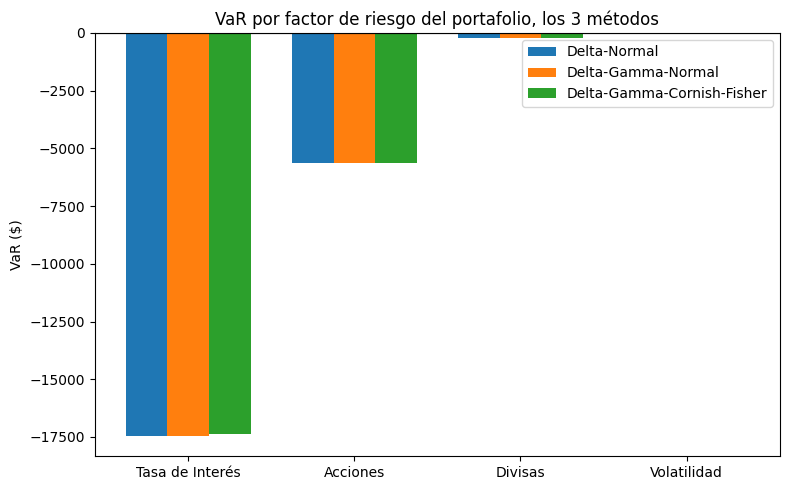

In [44]:
# @title 📋 Niveles 5-6: total portafolio por factor de riesgo, y total portafolio { display-mode: "both" }
resumen_nivel5_portafolio_factor = tabla_factor_portafolio
resumen_nivel6_portafolio_total = pd.DataFrame([fila_total_portafolio])

print("Nivel 5 — Total portafolio por factor de riesgo:")
display(resumen_nivel5_portafolio_factor)
print("\nNivel 6 — Total portafolio:")
display(resumen_nivel6_portafolio_total)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(resumen_nivel5_portafolio_factor))
ancho = 0.25
ax.bar(x - ancho, resumen_nivel5_portafolio_factor["VaR_DN"], ancho, label="Delta-Normal")
ax.bar(x, resumen_nivel5_portafolio_factor["VaR_DGN"], ancho, label="Delta-Gamma-Normal")
ax.bar(x + ancho, resumen_nivel5_portafolio_factor["VaR_DGCF"], ancho, label="Delta-Gamma-Cornish-Fisher")
ax.set_xticks(x)
ax.set_xticklabels(resumen_nivel5_portafolio_factor["Factor de riesgo"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("VaR ($)")
ax.set_title("VaR por factor de riesgo del portafolio, los 3 métodos")
ax.legend()
plt.tight_layout()
plt.show()


# ✅ Glosario y para seguir practicando

### Glosario rápido
- **Delta ($\delta$):** sensibilidad de primer orden del valor a un factor de riesgo.
- **Gamma ($\Gamma$):** sensibilidad de segundo orden (convexidad).
- **Theta ($\theta$):** sensibilidad al simple paso del tiempo (deriva determinista).
- **"Dollar" delta/gamma:** las mismas sensibilidades, reescaladas para usarse directamente con factores de riesgo en **retorno logarítmico** ($\delta\cdot X_0$, $\Gamma\cdot X_0X_0^\top$).
- **Delta-Normal:** VaR/CVaR usando solo el término lineal, asumiendo normalidad.
- **Delta-Gamma-Normal:** agrega el término cuadrático, pero sigue asumiendo normalidad (solo ajusta media y varianza).
- **Delta-Gamma-Cornish-Fisher:** además corrige el cuantil por la asimetría real que introduce el término cuadrático.
- **Matriz de bloques diagonal:** la forma en que se integra la $\Gamma$ de varios instrumentos — cada instrumento en su propio bloque, ceros fuera de la diagonal.

### 🧪 Ejercicios sugeridos
1. Compara el VaR Delta-Normal contra Delta-Gamma-Normal para las Opciones de tasa de interés: ¿por qué esperarías una diferencia más grande ahí que en, digamos, CETES?
2. Cambia `nivel_confianza` y observa cómo cambia el ajuste de Cornish-Fisher relativo a Delta-Gamma-Normal en niveles de confianza más extremos (99.5%).
3. Cambia `H_BUMP` (el tamaño del brinco del motor de Griegas) por un valor mucho más grande o más chico: ¿en qué punto empiezan a verse afectados los resultados? (así se justifica que 1e-4 es un tamaño razonable).
4. Compara `resumen_nivel5_portafolio_factor` (por tipo de factor) contra la suma de `resumen_nivel3_total_instrumento` (por instrumento): ¿por qué no dan lo mismo al sumar directamente los VaR, aunque sí coinciden si sumas las Delta/Gamma antes de calcular el VaR? (pista: diversificación / no-linealidad).
5. Agrega una posición nueva a cualquier instrumento y sigue su efecto en los 6 niveles del resumen integral.
